## Semantic Triage and Similar-Incident Retrieval for Aviation Safety Narratives

### 1. Get the data.
On the ASRS database site, search with date and anomaly filters. Export to CSV, at most 10,000 records per download, and merge several exports if you need more.

Colab has PyTorch, so install only what’s missing. Fix one seed so splits and runs are repeatable.

In [1]:
!pip -q install transformers datasets scikit-learn iterative-stratification sentence-transformers faiss-cpu bertopic gradio

import re, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
SEED = 42
random.seed(SEED); np.random.seed(SEED)

from pathlib import Path

### 2. Load the Dataset

Load the CSV. ASRS exports usually have two header rows (field group, then field name).

In [2]:
def load_asrs_csv(path):
    df = pd.read_csv(path, header=[0, 1], low_memory=False)
    df.columns = [f"{a} | {b}".strip() for a, b in df.columns]
    return df

def find_columns(df, *keywords):
    return [c for c in df.columns if all(k.lower() in c.lower() for k in keywords)]

In [3]:
#raw = load_asrs_csv("data/raw/asrs_export.csv")      # upload to Colab first
from google.colab import drive
drive.mount("/content/drive")

CSV_PATH = "/content/drive/MyDrive/asrs_export.csv"      # change to where you saved it
raw = pd.read_csv(CSV_PATH, low_memory=False)

print(raw.shape)
print(find_columns(raw, "narrative"))
print(find_columns(raw, "anomaly"))
print(find_columns(raw, "acn"))
raw.iloc[:2].T.head(40)

Mounted at /content/drive
(9000, 126)
['Report 1 | Narrative', 'Report 2 | Narrative']
['Events | Anomaly']
['ACN']


,0,1
ACN,2198935,2198951
Time | Date,202412.0,202501.0
Time | Local Time Of Day,1801-2400,1201-1800
Place | Locale Reference,Airport ZZZ.Airport,Airport ZZZ.Airport
Place | State Reference,US,US
Place | Relative Position.Angle.Radial,NaN,NaN
Place | Relative Position.Distance.Nautical Miles,NaN,NaN
Place | Altitude.AGL.Single Value,NaN,NaN
Place | Altitude.MSL.Single Value,Altitude.MSL.Single Value5000,NaN
Place | Latitude / Longitude (UAS),NaN,NaN


### 3. Clean the Data

Clean the text. Each function does one thing. The export also turned commas in the narratives into semicolons (“During climb out; the left main gear…”), so the cleaning step restores them. Redaction placeholders vary (ZZZ, ZZZ1, XXR, XXL), so they are mapped to one token each. Abbreviation expansion is a separate function so you can switch it on and off for the ablation.

In [4]:
import re, numpy as np, pandas as pd

def combine_narratives(df):
    return (df["Report 1 | Narrative"].fillna("") + " " + df["Report 2 | Narrative"].fillna("")).str.strip()

def normalise_placeholders(text):
    text = text.replace(";", ",")
    text = re.sub(r"\bZ{3,}\d*\b", "ZZZ", text)        # airports
    text = re.sub(r"\bXX+[LRC]?\b", "XX", text)         # runway numbers
    return re.sub(r"\s+", " ", text).strip()

ABBREV = {"ATC": "air traffic control", "FO": "first officer", "PF": "pilot flying", "PM": "pilot monitoring",
          "QRH": "quick reference handbook", "ILS": "instrument landing system",
          "TCAS": "traffic collision avoidance system", "VMC": "visual meteorological conditions",
          "IMC": "instrument meteorological conditions", "MEL": "minimum equipment list",
          "FBO": "fixed base operator", "MLG": "main landing gear", "RA": "resolution advisory",
          "TA": "traffic advisory", "VNAV": "vertical navigation", "FMS": "flight management system",
          "APU": "auxiliary power unit", "GPWS": "ground proximity warning system", "AGL": "above ground level",
          "MSL": "mean sea level", "IFR": "instrument flight rules", "VFR": "visual flight rules"}
_ABBREV_RE = re.compile(r"\b(" + "|".join(sorted(ABBREV, key=len, reverse=True)) + r")\b")

def expand_abbreviations(text):
    return _ABBREV_RE.sub(lambda m: ABBREV[m.group(1)], text)

def build_clean_table(df):
    out = pd.DataFrame({"acn": df["ACN"], "anomaly_raw": df["Events | Anomaly"], "text_raw": combine_narratives(df)})
    out["text"] = out["text_raw"].map(normalise_placeholders)
    out["text_expanded"] = out["text"].map(expand_abbreviations)
    out = out[out["text"].str.split().str.len() >= 10].dropna(subset=["anomaly_raw"])
    return out.drop_duplicates("acn").reset_index(drop=True)

df = build_clean_table(raw)
print(len(df))

8986


### 4. Build the Labels

The anomaly cell holds several codes separated by semicolons, such as "Conflict NMAC; Deviation - Altitude Overshoot". Take the top-level group from each code. Stray tokens like “Critical” and “Less Severe” don’t match any group, so they drop out automatically. Groups with fewer than 300 reports merge into Other.

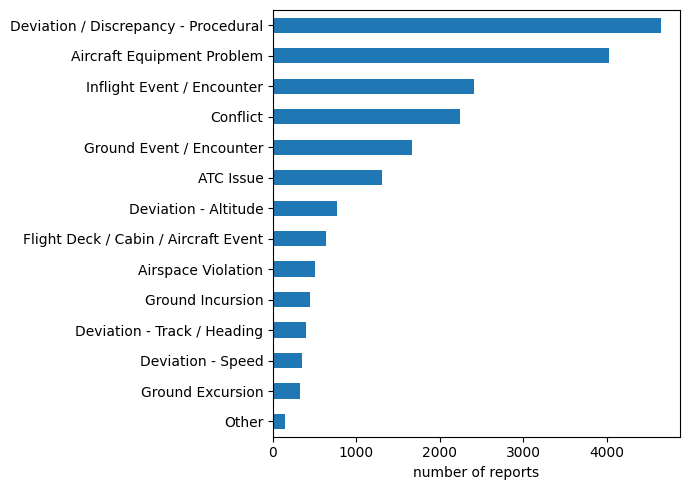

In [5]:
GROUPS = ["Deviation / Discrepancy - Procedural", "Deviation - Altitude", "Deviation - Track / Heading",
          "Deviation - Speed", "Aircraft Equipment Problem", "ATC Issue", "Conflict",
          "Inflight Event / Encounter", "Ground Event / Encounter", "Airspace Violation",
          "Flight Deck / Cabin / Aircraft Event", "Ground Excursion", "Ground Incursion",
          "No Specific Anomaly Occurred"]

def parse_anomaly_groups(cell):
    items = [i.strip() for i in str(cell).split(";")]
    return sorted({g for i in items for g in GROUPS if i.startswith(g)})

def build_label_matrix(anomaly_series):
    groups = anomaly_series.map(parse_anomaly_groups)
    return pd.DataFrame({g: groups.map(lambda gs, g=g: int(g in gs)) for g in GROUPS}, index=anomaly_series.index)

def merge_rare_groups(Y, min_count=300):
    rare = [c for c in Y.columns if Y[c].sum() < min_count]
    Y = Y.copy()
    if rare:
        Y["Other"] = Y[rare].max(axis=1)
        Y = Y.drop(columns=rare)
    return Y

def plot_label_counts(Y):
    import matplotlib.pyplot as plt
    Y.sum().sort_values().plot.barh(figsize=(7, 5))
    plt.xlabel("number of reports"); plt.tight_layout(); plt.show()

Y = merge_rare_groups(build_label_matrix(df["anomaly_raw"]))
plot_label_counts(Y)

### 5. Split the Data

Each row is one report, so grouping by report is automatic. Iterative stratification keeps rare groups in all three sets. Before splitting, near-duplicates (TF-IDF cosine at or above 0.95) are checked.

In [6]:
def find_near_duplicates(texts, threshold=0.95, chunk=1000):
    from sklearn.feature_extraction.text import TfidfVectorizer
    X = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    pairs = []
    for s in range(0, X.shape[0], chunk):
        sim = (X[s:s + chunk] @ X.T).toarray()
        for r in range(sim.shape[0]):
            sim[r, s + r] = 0
        rows, cols = np.where(sim >= threshold)
        pairs += [(s + r, c) for r, c in zip(rows, cols) if s + r < c]
    return pairs

def split_multilabel(Y, seed=42, val=0.15, test=0.15):
    from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
    idx, y = np.arange(len(Y)), Y.values
    tr, rest = next(MultilabelStratifiedShuffleSplit(n_splits=1, test_size=val + test, random_state=seed).split(idx, y))
    v, t = next(MultilabelStratifiedShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed).split(rest, y[rest]))
    return tr, rest[v], rest[t]

pairs = find_near_duplicates(df["text"])
drop = {j for _, j in pairs}
keep = [i for i in range(len(df)) if i not in drop]
df, Y = df.iloc[keep].reset_index(drop=True), Y.iloc[keep].reset_index(drop=True)
train_i, val_i, test_i = split_multilabel(Y)
print(len(train_i), len(val_i), len(test_i))

out_dir = Path("/content/drive/MyDrive/asrs_processed")
out_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(out_dir / "clean.csv", index=False)
Y.to_csv(out_dir / "labels.csv", index=False)
np.savez(out_dir / "split.npz", train=train_i, val=val_i, test=test_i)

6267 1338 1358


### 6. TF-IDF + one-vs-rest logistic regression

The TF-IDF baseline gives  the first real numbers and the reference point for DistilBERT.

**Features:** Unigrams and Bigrams, lowercased, with sublinear term weighting. Words in fewer than 3 reports are dropped.

**Model:** One logistic regression per anomaly group, with balanced class weights so rare groups aren’t ignored.

**Thresholds:** Each group gets its own decision threshold, tuned on the validation set.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score, precision_recall_fscore_support

def build_tfidf(train_texts, other_texts):
    vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, max_df=0.9,
                          sublinear_tf=True, max_features=100_000)
    return vec.fit_transform(train_texts), [vec.transform(t) for t in other_texts], vec

def train_ovr_logreg(X, Y, C=4.0):
    clf = OneVsRestClassifier(LogisticRegression(C=C, class_weight="balanced", max_iter=1000, solver="liblinear"))
    return clf.fit(X, Y)

def tune_thresholds(proba, Y):
    grid = np.arange(0.1, 0.91, 0.05)
    return np.array([grid[np.argmax([f1_score(Y[:, j], proba[:, j] >= t, zero_division=0) for t in grid])]
                     for j in range(Y.shape[1])])

def evaluate_multilabel(proba, Y, thresholds, names):
    pred = (proba >= thresholds).astype(int)
    p, r, f, s = precision_recall_fscore_support(Y, pred, zero_division=0)
    per = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=names).round(3)
    return {"macro_f1": f1_score(Y, pred, average="macro", zero_division=0),
            "micro_f1": f1_score(Y, pred, average="micro", zero_division=0)}, per

def plot_per_group_f1(per_tables):
    import matplotlib.pyplot as plt
    pd.DataFrame({k: v["f1"] for k, v in per_tables.items()}).sort_values(list(per_tables)[0]).plot.barh(figsize=(8, 6))
    plt.xlabel("F1 (validation)"); plt.tight_layout(); plt.show()

text {'macro_f1': 0.689, 'micro_f1': 0.776}
text_expanded {'macro_f1': 0.69, 'micro_f1': 0.774}


,precision,recall,f1,support
Deviation / Discrepancy - Procedural,0.624,0.895,0.736,695
Deviation - Altitude,0.561,0.684,0.617,114
Deviation - Track / Heading,0.483,0.500,0.492,58
Deviation - Speed,0.717,0.647,0.680,51
Aircraft Equipment Problem,0.906,0.912,0.909,604
ATC Issue,0.702,0.741,0.721,197
Conflict,0.938,0.896,0.916,336
Inflight Event / Encounter,0.776,0.845,0.809,361
Ground Event / Encounter,0.627,0.792,0.700,250
Airspace Violation,0.786,0.743,0.764,74


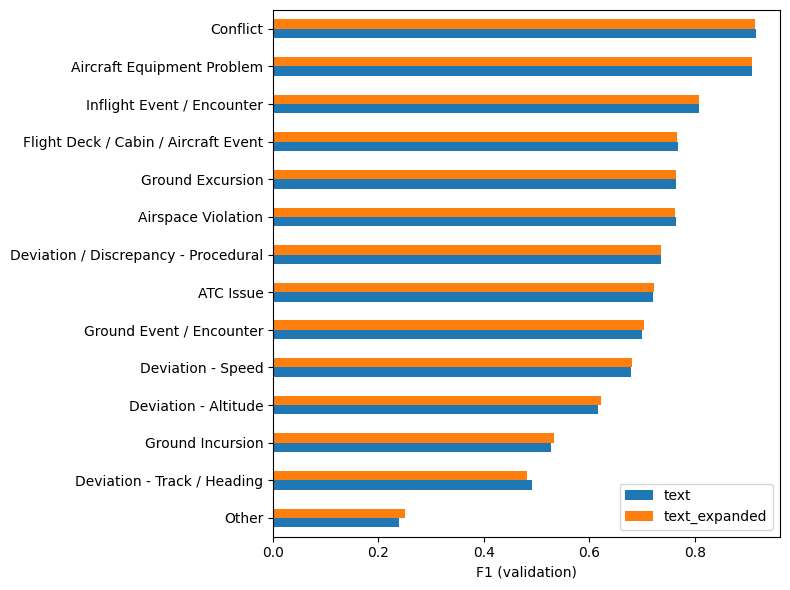

In [8]:
res, pers = {}, {}
for col in ("text", "text_expanded"):
    Xtr, (Xva,), _ = build_tfidf(df[col].iloc[train_i], [df[col].iloc[val_i]])
    clf = train_ovr_logreg(Xtr, Y.values[train_i])
    pv = clf.predict_proba(Xva)
    th = tune_thresholds(pv, Y.values[val_i])
    res[col], pers[col] = evaluate_multilabel(pv, Y.values[val_i], th, Y.columns)
    print(col, {k: round(v, 3) for k, v in res[col].items()})
display(pers["text"]); plot_per_group_f1(pers)

### 7. Training DistilBERT

Train DistilBERT as a multi-label classifier, three seeds, and compare it with the TF-IDF baseline.

In [9]:
!pip -q install transformers accelerate
import torch, numpy as np, pandas as pd
from torch.utils.data import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments, set_seed
from sklearn.metrics import f1_score

print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU: switch the runtime")

Tesla T4


**1) Tokenise with head-and-tail truncation:**

DistilBERT reads at most 512 tokens, and about 22% of the narratives are longer. Instead of cutting the end, keep the first 128 tokens and the last 384, because ASRS narratives often open with the situation and close with the outcome. The dataset class returns variable-length ids, and a small collator pads each batch to its longest item.

In [10]:
MODEL_NAME, MAX_LEN = "distilbert-base-uncased", 512
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def head_tail_ids(text, tokenizer, max_len=MAX_LEN):
    head = max_len // 4
    ids = tokenizer(text, add_special_tokens=False)["input_ids"]
    room = max_len - 2
    if len(ids) > room:
        ids = ids[:head] + ids[-(room - head):]
    return [tokenizer.cls_token_id] + ids + [tokenizer.sep_token_id]

class NarrativeDataset(Dataset):
    def __init__(self, texts, Y, tokenizer):
        self.ids = [head_tail_ids(t, tokenizer) for t in texts]
        self.Y = torch.tensor(np.asarray(Y), dtype=torch.float)
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        return {"input_ids": self.ids[i], "attention_mask": [1] * len(self.ids[i]), "labels": self.Y[i]}

def make_collator(tokenizer):
    def collate(batch):
        n = max(len(b["input_ids"]) for b in batch)
        ids = torch.full((len(batch), n), tokenizer.pad_token_id, dtype=torch.long)
        mask = torch.zeros((len(batch), n), dtype=torch.long)
        for i, b in enumerate(batch):
            L = len(b["input_ids"]); ids[i, :L] = torch.tensor(b["input_ids"]); mask[i, :L] = 1
        return {"input_ids": ids, "attention_mask": mask, "labels": torch.stack([b["labels"] for b in batch])}
    return collate

train_ds = NarrativeDataset(df["text"].iloc[train_i], Y.values[train_i], tokenizer)
val_ds = NarrativeDataset(df["text"].iloc[val_i], Y.values[val_i], tokenizer)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (771 > 512). Running this sequence through the model will result in indexing errors


**2) Weighted loss:**

The model has one sigmoid output per group and uses binary cross-entropy. Rare groups get a larger positive weight, the square root of negatives over positives, so a rare group like Other counts more without dominating training.

In [11]:
def compute_pos_weight(Y):
    pos = Y.sum(axis=0); neg = len(Y) - pos
    return torch.tensor(np.sqrt(neg / np.maximum(pos, 1)), dtype=torch.float)

class WeightedBCETrainer(Trainer):
    def __init__(self, *args, pos_weight=None, **kwargs):
        super().__init__(*args, **kwargs); self.pos_weight = pos_weight
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = torch.nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(outputs.logits.device))(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss

def macro_f1_at_half(eval_pred):
    logits, labels = eval_pred
    pred = (1 / (1 + np.exp(-logits)) >= 0.5).astype(int)
    return {"macro_f1_at_0.5": f1_score(labels, pred, average="macro", zero_division=0)}

**3) One training run:**

Learning rate: 3e-5, batch size: 16, 4 epochs, weight decay: 0.01, 10% warm-up, AdamW. The seed is a parameter, and each run saves its model to Drive so the test set can use it at the end.

In [12]:
def train_distilbert(seed, train_ds, val_ds, pos_weight, n_labels, tokenizer, out_dir, epochs=4, lr=3e-5, bs=16):
    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=n_labels, problem_type="multi_label_classification")
    args = TrainingArguments(output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr, weight_decay=0.01,
        warmup_steps=int(0.1 * epochs * -(-len(train_ds) // bs)), per_device_train_batch_size=bs,
        per_device_eval_batch_size=32, eval_strategy="epoch", save_strategy="no", logging_steps=50,
        report_to="none", fp16=torch.cuda.is_available(), seed=seed, remove_unused_columns=False)
    trainer = WeightedBCETrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
        data_collator=make_collator(tokenizer), compute_metrics=macro_f1_at_half, pos_weight=pos_weight)
    trainer.train()
    trainer.save_model(out_dir)
    return trainer

def predict_proba(trainer, ds):
    return 1 / (1 + np.exp(-trainer.predict(ds).predictions))

**4) Evaluate:**

Three seeds, then evaluate. Thresholds are tuned on the validation set exactly as for the baseline, so the comparison is fair. The test set stays untouched.

In [13]:
MODELS_DIR = "/content/drive/MyDrive/asrs-copilot/models"
pos_weight = compute_pos_weight(Y.values[train_i])
bert_res, bert_pers, val_probs = {}, {}, {}
for seed in (1, 2, 3):
    trainer = train_distilbert(seed, train_ds, val_ds, pos_weight, Y.shape[1], tokenizer, f"{MODELS_DIR}/distilbert_seed{seed}")
    pv = predict_proba(trainer, val_ds)
    th = tune_thresholds(pv, Y.values[val_i])
    bert_res[seed], bert_pers[seed] = evaluate_multilabel(pv, Y.values[val_i], th, Y.columns)
    val_probs[seed] = pv
    np.save(f"{MODELS_DIR}/val_probs_seed{seed}.npy", pv)
    print(seed, {k: round(v, 3) for k, v in bert_res[seed].items()})
    del trainer; torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1 At 0.5
1,0.392766,0.362666,0.591835
2,0.294412,0.307614,0.641312
3,0.259217,0.291494,0.661442
4,0.226331,0.284688,0.681911


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1 At 0.5
1,0.395948,0.354503,0.589380
2,0.306377,0.302557,0.660754
3,0.262114,0.283488,0.677379
4,0.226031,0.282166,0.685232


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

3 {'macro_f1': 0.705, 'micro_f1': 0.773}


**5) Compare with the baseline:**

One function computes the summary and a separate one plots it.

DistilBERT macro-F1: 0.702 ± 0.004 vs baseline 0.689


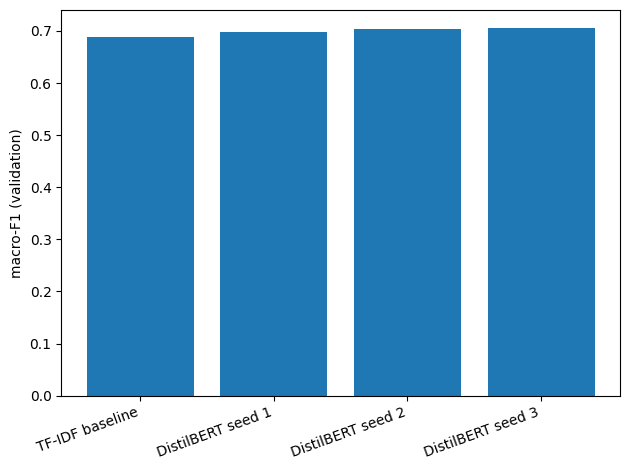

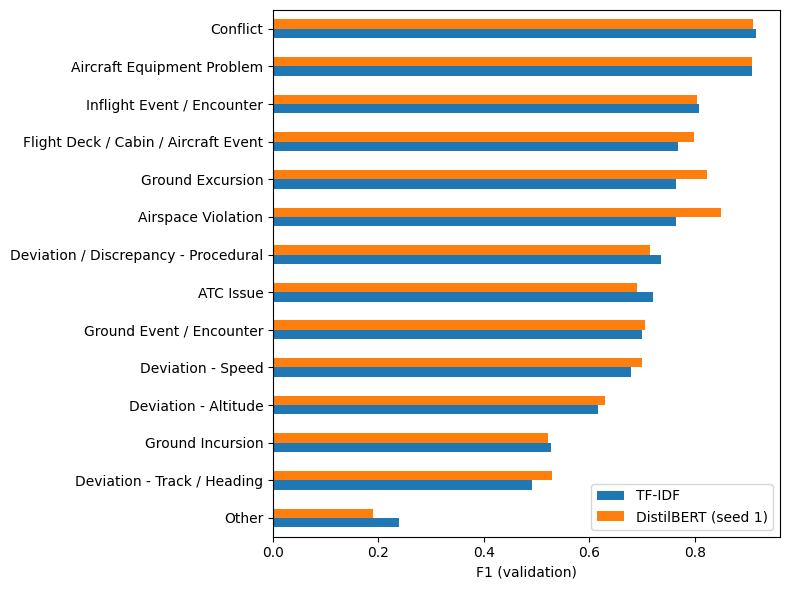

In [14]:
def summarise_seeds(results):
    m = [r["macro_f1"] for r in results.values()]
    return float(np.mean(m)), float(np.std(m, ddof=1))

def plot_macro_comparison(baseline, bert_results):
    import matplotlib.pyplot as plt
    labels = ["TF-IDF baseline"] + [f"DistilBERT seed {s}" for s in bert_results]
    vals = [baseline] + [r["macro_f1"] for r in bert_results.values()]
    plt.bar(labels, vals); plt.xticks(rotation=20, ha="right"); plt.ylabel("macro-F1 (validation)"); plt.tight_layout(); plt.show()

mean, sd = summarise_seeds(bert_res)
print(f"DistilBERT macro-F1: {mean:.3f} ± {sd:.3f} vs baseline {res['text']['macro_f1']:.3f}")
plot_macro_comparison(res["text"]["macro_f1"], bert_res)
plot_per_group_f1({"TF-IDF": pers["text"], "DistilBERT (seed 1)": bert_pers[1]})

### 8. Sentence Embeddings and the FAISS index

What this phase produces:

1) Two sets of 384-dimensional embeddings, one per way of handling long narratives, so phase 10 can compare them:
- Truncated: MiniLM reads only the first 256 word pieces of each narrative and ignores the rest.
- Chunked: each narrative is cut into sentence windows of about 200 tokens, each window is embedded, and the window vectors are averaged and re-normalised.
2) A FAISS index of past reports (the training split) that you can query with new narratives.

In [15]:
!pip -q install sentence-transformers faiss-cpu
import re, numpy as np
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
model.max_seq_length = 256
print(model.get_sentence_embedding_dimension())    # 384

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

384


/tmp/ipykernel_1362/883180405.py:7: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print(model.get_sentence_embedding_dimension())    # 384


**Step 1:** Embedding functions. One function per technique. Vectors are L2-normalised, so the inner product equals cosine similarity.

In [16]:
SENT_RE = re.compile(r'(?<=[.!?])\s+')

def chunk_text(text, tokenizer, max_tokens=200):
    sents, chunks, cur, cur_n = SENT_RE.split(text), [], [], 0
    for s in sents:
        n = len(tokenizer(s, add_special_tokens=False)["input_ids"])
        if cur and cur_n + n > max_tokens:
            chunks.append(" ".join(cur)); cur, cur_n = [], 0
        cur.append(s); cur_n += n
    if cur: chunks.append(" ".join(cur))
    return chunks

def embed_truncated(model, texts, batch_size=64):
    return model.encode(list(texts), batch_size=batch_size, normalize_embeddings=True,
                        show_progress_bar=True).astype("float32")

def embed_chunked(model, texts, max_tokens=200, batch_size=64):
    chunks, owner = [], []
    for i, t in enumerate(texts):
        cs = chunk_text(t, model.tokenizer, max_tokens)
        chunks += cs; owner += [i] * len(cs)
    ce = model.encode(chunks, batch_size=batch_size, normalize_embeddings=True, show_progress_bar=True)
    out = np.zeros((len(texts), ce.shape[1]), dtype="float32")
    np.add.at(out, np.array(owner), ce)
    return (out / np.linalg.norm(out, axis=1, keepdims=True)).astype("float32")

**Step 2:** Embed every narrative and save. Use the text column (not the abbreviation-expanded one) for the main run. Saving to Drive means you won’t recompute after a restart, and phase 10 (BERTopic) reuses these vectors.

In [17]:
EMB_DIR = "/content/drive/MyDrive/asrs-copilot/embeddings"
import os; os.makedirs(EMB_DIR, exist_ok=True)

emb_trunc = embed_truncated(model, df["text"])
emb_chunk = embed_chunked(model, df["text"])
np.save(f"{EMB_DIR}/emb_trunc.npy", emb_trunc)
np.save(f"{EMB_DIR}/emb_chunk.npy", emb_chunk)
print(emb_trunc.shape, emb_chunk.shape)             # (rows, 384) each

Batches:   0%|          | 0/141 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (329 > 256). Running this sequence through the model will result in indexing errors


Batches:   0%|          | 0/328 [00:00<?, ?it/s]

(8963, 384) (8963, 384)


**Step 3:** Build the index and search. The index holds only the training narratives, which play the role of past reports. Validation narratives act as new incoming reports, and the test set stays untouched.

In [18]:
import faiss

def build_faiss_index(emb):
    index = faiss.IndexFlatIP(emb.shape[1])     # exact search; fine for ~6,000 vectors
    index.add(emb)
    return index

def search_similar(index, query_emb, k=5):
    return index.search(query_emb, k)

def show_neighbours(df_query, df_index, scores, ids, row, n_chars=220):
    print("QUERY:", df_query["text"].iloc[row][:n_chars], "\n   anomalies:", df_query["anomaly_raw"].iloc[row][:120])
    for s, j in zip(scores[row], ids[row]):
        print(f"  {s:.3f} | {df_index['text'].iloc[j][:n_chars]}\n          anomalies: {df_index['anomaly_raw'].iloc[j][:120]}")

In [19]:
index_chunk = build_faiss_index(emb_chunk[train_i])
index_trunc = build_faiss_index(emb_trunc[train_i])

df_train, df_val = df.iloc[train_i].reset_index(drop=True), df.iloc[val_i].reset_index(drop=True)
scores, ids = search_similar(index_chunk, emb_chunk[val_i], k=5)
for r in (0, 1, 2):
    show_neighbours(df_val, df_train, scores, ids, r)
    print()

QUERY: Received amber LPV which later downgraded to amber L/VNAV with amber BOTH ON GPS1. When I contacted maintenance, they indicated that they and the Chief Pilot were well aware of the solar activity affecting GPS systems. I 
   anomalies: Aircraft Equipment Problem Less Severe; Inflight Event / Encounter Other / Unknown
  0.555 | Shortly before beginning the descent for arrival into PVR, we lost the GPS-R and then the GPS-L signal (GPS-R/L INVALID FMC messages). Over the last many (6+?) months, I have seen loss of usually one, occasionally both, 
          anomalies: Aircraft Equipment Problem Less Severe
  0.547 | At approximately XA58 and approximately at position N25 50.5 W107 34.0. We encountered multiple amber messages associated with Jamming. We proceeded to request a heading from ATC while we trouble shoot. Amber EICAS msg T
          anomalies: Aircraft Equipment Problem Less Severe
  0.544 | While enroute and upon initial check-in with Albuquerque Center, our aircraft was 

### 9. Retrieval evaluation:

Precision@5 and @10 with Jaccard ≥ 0.5, against a TF-IDF keyword baseline, plus your manual rubric on 30 queries

In [20]:
# ---------- 1. retrievers (each returns neighbour ids into the train set, shape n_queries x k) ----------
def tfidf_top_k(train_texts, query_texts, k=10, batch=500):
    Xt, (Xq,), _ = build_tfidf(train_texts, [query_texts])           # reuses the phase 5 vectoriser settings
    ids = np.zeros((Xq.shape[0], k), dtype=int)
    for s in range(0, Xq.shape[0], batch):
        S = (Xq[s:s + batch] @ Xt.T).toarray()                       # cosine, since tf-idf rows are unit length
        part = np.argpartition(-S, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(S, part, 1), axis=1)
        ids[s:s + batch] = np.take_along_axis(part, order, 1)
    return ids

def embedding_top_k(index, query_emb, k=10):
    _, ids = search_similar(index, query_emb, k)                     # phase 7 function
    return ids

def random_top_k(n_queries, n_index, k=10, seed=0):
    rng = np.random.default_rng(seed)                                # sanity floor: what chance looks like
    return rng.integers(0, n_index, size=(n_queries, k))

def collapse_chunk_hits(index, query_emb, owner, k=10, overfetch=5):
    # for the chunked index (ablation): several chunks can belong to one report, so keep the first k unique reports
    _, cid = index.search(query_emb, k * overfetch)
    out = np.zeros((len(cid), k), dtype=int)
    for i, row in enumerate(cid):
        seen = list(dict.fromkeys(owner[row]))[:k]
        out[i, :len(seen)] = seen
    return out

# ---------- 2. relevance proxy: Jaccard overlap of anomaly-group sets >= 0.5 ----------
def relevance_hits(Y_query, Y_index, ids, thr=0.5):
    q = Y_query.astype(bool)[:, None, :]
    nb = Y_index.astype(bool)[ids]                                   # n_queries x k x 14
    inter, union = (nb & q).sum(-1), (nb | q).sum(-1)
    return (inter / np.maximum(union, 1)) >= thr                     # boolean n_queries x k

def precision_at_k(hits, k):
    return hits[:, :k].mean(axis=1)                                  # one value per query

# ---------- 3. statistics ----------
def mean_ci(x, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), (n_boot, len(x)))].mean(axis=1)
    return x.mean(), *np.percentile(means, [2.5, 97.5])

def paired_bootstrap_diff(a, b, n_boot=5000, seed=0):
    # H2: is embedding precision higher than tf-idf precision, query by query?
    d = a - b
    rng = np.random.default_rng(seed)
    means = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(axis=1)
    return d.mean(), np.percentile(means, [2.5, 97.5]), (means <= 0).mean()   # last value ~ one-sided p

def build_retrieval_table(ids_by_method, Y_query, Y_index, ks=(5, 10), thr=0.5):
    keep = Y_query.sum(1) > 0                                        # queries with no labels have no proxy truth
    rows, per_query = [], {}
    for name, ids in ids_by_method.items():
        hits = relevance_hits(Y_query[keep], Y_index, ids[keep], thr)
        row = {"method": name}
        for k in ks:
            pq = precision_at_k(hits, k)
            m, lo, hi = mean_ci(pq)
            row[f"P@{k}"], row[f"P@{k} 95% CI"] = round(m, 3), f"[{lo:.3f}, {hi:.3f}]"
            per_query[(name, k)] = pq
        rows.append(row)
    return pd.DataFrame(rows), per_query

# ---------- 4. plot ----------
def plot_precision_bars(table, ks=(5, 10)):
    x, w = np.arange(len(table)), 0.38
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for j, k in enumerate(ks):
        ax.bar(x + (j - 0.5) * w, table[f"P@{k}"], w, label=f"P@{k}")
    ax.set_xticks(x); ax.set_xticklabels(table["method"]); ax.set_ylabel("Precision (Jaccard ≥ 0.5)")
    ax.set_ylim(0, 1); ax.legend(); ax.set_title("Retrieval precision on validation queries")
    plt.tight_layout(); plt.show()

# ---------- 5. manual rubric (30 queries, blind to method) ----------
def make_rubric_sheet(val_df, train_df, ids_by_method, Y_val, n=30, k=5, seed=42,
                      sheet_path="rubric_sheet.csv", key_path="rubric_key.csv"):
    rng = np.random.default_rng(seed)
    qs = rng.choice(np.where(Y_val.sum(1) > 0)[0], size=n, replace=False)
    sheet, key = [], []
    for qi, q in enumerate(qs):
        cands = {}
        for m, ids in ids_by_method.items():
            for j in ids[q, :k]:
                cands.setdefault(int(j), []).append(m)
        order = list(cands); rng.shuffle(order)                      # shuffled, so you cannot tell which method found it
        for j in order:
            sheet.append({"qid": qi, "query": val_df["text"].iloc[q][:600],
                          "candidate_id": j, "candidate": train_df["text"].iloc[j][:600], "score": ""})
            key += [{"qid": qi, "candidate_id": j, "method": m} for m in cands[j]]
    pd.DataFrame(sheet).to_csv(sheet_path, index=False); pd.DataFrame(key).to_csv(key_path, index=False)
    return len(sheet)

def score_rubric_sheet(sheet_path="rubric_sheet.csv", key_path="rubric_key.csv"):
    sheet, key = pd.read_csv(sheet_path), pd.read_csv(key_path)      # score: 2 = same issue, 1 = related, 0 = unrelated
    m = key.merge(sheet[["qid", "candidate_id", "score"]], on=["qid", "candidate_id"])
    return m.groupby("method")["score"].agg(["mean", "count"]).round(3)

### 10. Theme discovery with BERTopic:
Scored by C_v coherence. It doesn’t test H1–H3. It supports the “themes” part.

In [21]:
# ---------- 1. build the topic model (reuses the MiniLM vectors, no re-embedding) ----------
def build_topic_model(texts, embeddings, min_cluster_size=30, seed=42, extra_stop=("zzz", "zzz1", "xxr", "xxl")):
    from bertopic import BERTopic
    from umap import UMAP
    from hdbscan import HDBSCAN
    from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
    stop = list(ENGLISH_STOP_WORDS.union(extra_stop))               # swap in your actual placeholder tag if it differs
    umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=seed)
    hdb = HDBSCAN(min_cluster_size=min_cluster_size, min_samples=10, metric="euclidean",
                  cluster_selection_method="eom", prediction_data=True)
    vec = CountVectorizer(stop_words=stop, ngram_range=(1, 2), min_df=5)   # c-TF-IDF is computed on these counts
    model = BERTopic(embedding_model=None, umap_model=umap_model, hdbscan_model=hdb,
                     vectorizer_model=vec, calculate_probabilities=False, verbose=False)
    topics, _ = model.fit_transform(list(texts), embeddings=embeddings)
    return model, np.array(topics)

# ---------- 2. compute: overview, outliers, coherence, link to anomaly labels ----------
def topic_overview(model):
    info = model.get_topic_info()
    return info[info["Topic"] != -1][["Topic", "Count", "Name"]].reset_index(drop=True)

def outlier_share(topics):
    return float((topics == -1).mean())                              # HDBSCAN leaves unclustered reports as topic -1

def compute_cv_coherence(model, texts, top_n=10):
    from gensim.corpora import Dictionary
    from gensim.models.coherencemodel import CoherenceModel
    analyzer = model.vectorizer_model.build_analyzer()              # same tokens and bigrams the topics were built from
    tokens = [analyzer(t) for t in texts]
    dic = Dictionary(tokens)
    ids, words = [], []
    for t in model.get_topics():
        if t == -1:
            continue
        w = [x for x, _ in model.get_topic(t)[:top_n] if x in dic.token2id]
        if len(w) > 1:
            ids.append(t); words.append(w)
    cm = CoherenceModel(topics=words, texts=tokens, dictionary=dic, coherence="c_v", processes=1)
    return cm.get_coherence(), dict(zip(ids, cm.get_coherence_per_topic()))

def topic_label_profile(topics, Y, label_names):
    df = pd.DataFrame(Y, columns=label_names)
    df["topic"] = topics
    df = df[df["topic"] != -1]
    prof = df.groupby("topic")[list(label_names)].mean()            # share of each topic's reports carrying each group
    prof["size"] = df.groupby("topic").size()
    return prof.sort_values("size", ascending=False)

def sample_topic_docs(texts, topics, topic_id, n=3, seed=0, chars=300):
    idx = np.where(topics == topic_id)[0]
    pick = np.random.default_rng(seed).choice(idx, size=min(n, len(idx)), replace=False)
    return [texts.iloc[i][:chars] for i in pick]

def sweep_min_cluster_size(texts, embeddings, sizes=(20, 30, 50, 80), seed=42):
    rows = []
    for s in sizes:
        m, tp = build_topic_model(texts, embeddings, min_cluster_size=s, seed=seed)
        cv, _ = compute_cv_coherence(m, texts)
        rows.append({"min_cluster_size": s, "n_topics": len(set(tp)) - (1 if -1 in tp else 0),
                     "outlier_share": round(outlier_share(tp), 3), "C_v": round(cv, 3)})
    return pd.DataFrame(rows)

# ---------- 3. plots ----------
def plot_topic_sizes(overview, top=15):
    d = overview.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 5.5))
    ax.barh(d["Name"].str[:45], d["Count"])
    ax.set_xlabel("Reports in topic"); ax.set_title(f"Largest {len(d)} topics")
    plt.tight_layout(); plt.show()

def plot_topic_label_heatmap(profile, top=15):
    d = profile.head(top)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    im = ax.imshow(d.drop(columns="size").values, aspect="auto", cmap="YlOrBr", vmin=0, vmax=1)
    ax.set_xticks(range(d.shape[1] - 1)); ax.set_xticklabels(d.columns[:-1], rotation=60, ha="right")
    ax.set_yticks(range(len(d))); ax.set_yticklabels([f"topic {t} (n={n})" for t, n in zip(d.index, d["size"])])
    fig.colorbar(im, label="share of topic with anomaly group"); plt.tight_layout(); plt.show()

def plot_sweep(table):
    fig, ax1 = plt.subplots(figsize=(6, 4))
    ax1.plot(table["min_cluster_size"], table["C_v"], marker="o", label="C_v")
    ax1.set_xlabel("min_cluster_size"); ax1.set_ylabel("C_v coherence")
    ax2 = ax1.twinx(); ax2.plot(table["min_cluster_size"], table["outlier_share"], marker="s", color="tab:red")
    ax2.set_ylabel("outlier share"); plt.tight_layout(); plt.show()

In [22]:
from sentence_transformers import SentenceTransformer

# if you removed near-duplicates in phase 4, do it here on df BEFORE the labels and split:
# pairs = find_near_duplicates(df["text"])
# df = df.drop(index=sorted({j for _, j in pairs})).reset_index(drop=True)

if "Y" not in globals():
    Y = merge_rare_groups(build_label_matrix(df["anomaly_raw"]), min_count=300)
if "train_i" not in globals():
    train_i, val_i, test_i = split_multilabel(Y)

train_df = df.iloc[train_i].reset_index(drop=True)
val_df   = df.iloc[val_i].reset_index(drop=True)
Y_train, Y_val = Y.values[train_i], Y.values[val_i]
label_names = list(Y.columns)

if "model" not in globals():
    model = SentenceTransformer("all-MiniLM-L6-v2")
if "emb_train" not in globals():
    emb_train = embed_truncated(model, train_df["text"])
    emb_val   = embed_truncated(model, val_df["text"])
index = build_faiss_index(emb_train)

print(len(df), len(train_df), len(val_df), Y.shape, emb_train.shape)

Batches:   0%|          | 0/98 [00:00<?, ?it/s]

Batches:   0%|          | 0/21 [00:00<?, ?it/s]

8963 6267 1338 (8963, 14) (6267, 384)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 70.7 MB/s  0:00:00
   min_cluster_size  n_topics  outlier_share    C_v
0                20        52          0.313  0.733
1                30        42          0.321  0.740
2                50        38          0.336  0.749
3                80         5          0.005  0.711


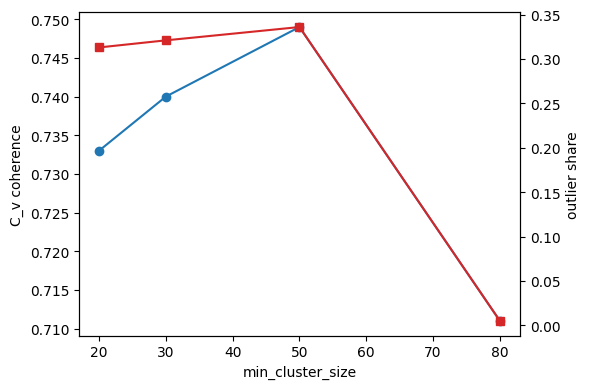

    Topic  Count                                            Name
0       0    492                     0_runway_left_right_student
1       1    428             1_pattern_aircraft_traffic_downwind
2       2    235                         2_smoke_smell_odor_crew
3       3    207                     3_engine_power_rpm_throttle
4       4    200  4_turbulence_severe_moderate_severe turbulence
5       5    196                       5_gate_vehicle_ramp_truck
6       6    191                        6_door_slide_agent_doors
7       7    172      7_cabin_cabin altitude_pack_pressurization
8       8    172            8_airspace_drone_laanc_authorization
9       9    159                     9_hydraulic_hyd_qrh_landing
10     10    157                        10_drone_object_feet_saw
11     11    148                   11_gps_jamming_navigation_rnp
12     12    135               12_taxiway_taxi_runway_hold short
13     13    130               13_approach_visual_glide_altitude
14     14    122         

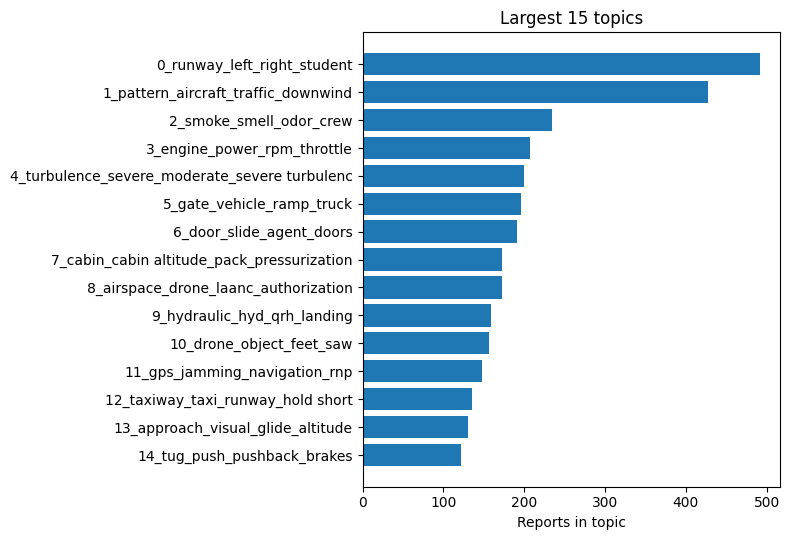

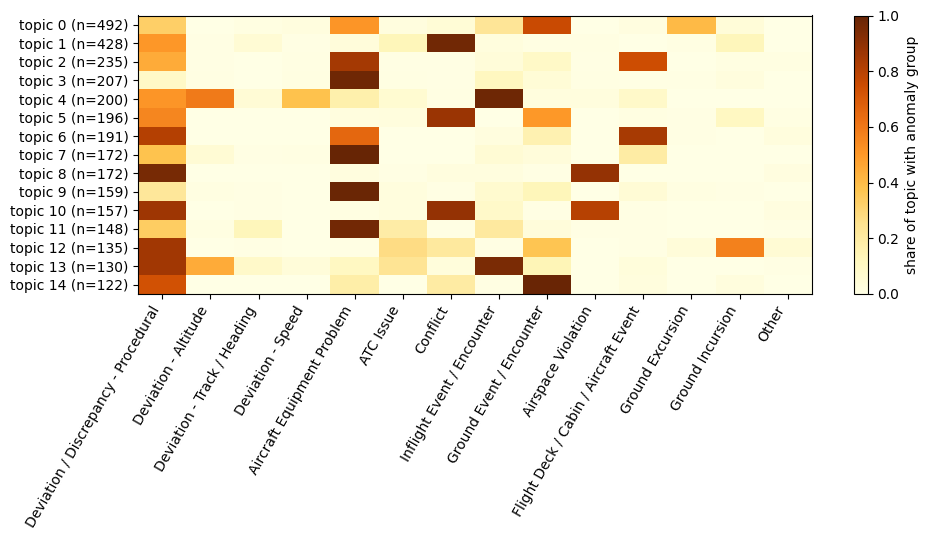

0
  [('runway', np.float64(0.024326678271094502)), ('left', np.float64(0.019604642432141675)), ('right', np.float64(0.018851373900963312)), ('student', np.float64(0.01857070175712157)), ('rudder', np.float64(0.017841507545887158)), ('aircraft', np.float64(0.017585751880688238))]
  While training the student pilot in students owned and built experimental aircraft, 3 previous uneventful landings were performed, on the 4th landing a full stop landing was planned. The landing was uneventful until rollout when the student noticed that the right brake had failed and we would miss t
  Today we are conducting a normal flight at ZZZ. Upon landing the airplane pulled hard to the left so we pulled the power, and got on the brakes. We shut down on the runway and discovered that we had a flat left main tire. We called flight service to close the airport since it was early in the mornin
  Tire was found in the unserviceable rack in ZZZ still inflated, suspected it was shipped this way from an out st

In [23]:
!pip install gensim bertopic

texts_tv = pd.concat([train_df["text"], val_df["text"]], ignore_index=True)
emb_tv   = np.vstack([emb_train, emb_val])
Y_tv     = np.vstack([Y_train, Y_val])

sweep = sweep_min_cluster_size(texts_tv, emb_tv)
print(sweep); plot_sweep(sweep)

model, topics = build_topic_model(texts_tv, emb_tv, min_cluster_size=30)   # pick the size after reading the sweep
overview = topic_overview(model); print(overview.head(15))
cv, cv_by_topic = compute_cv_coherence(model, texts_tv)
print(f"C_v = {cv:.3f}, topics = {len(overview)}, outliers = {outlier_share(topics):.1%}")

profile = topic_label_profile(topics, Y_tv, label_names)
plot_topic_sizes(overview); plot_topic_label_heatmap(profile)
for t in overview["Topic"].head(5):
    print(t, model.get_topic(t)[:6], *sample_topic_docs(texts_tv, topics, t), sep="\n  ")

In [24]:
def seed_stability(texts, embeddings, seeds=(0, 1, 2), min_cluster_size=30):
    from sklearn.metrics import adjusted_rand_score
    runs = {}
    for s in seeds:
        m, tp = build_topic_model(texts, embeddings, min_cluster_size, seed=s)
        cv, _ = compute_cv_coherence(m, texts)
        runs[s] = (tp, cv)
    table = pd.DataFrame([{"seed": s, "n_topics": len(set(tp)) - (-1 in tp),
                           "outlier_share": round(outlier_share(tp), 3), "C_v": round(cv, 3)}
                          for s, (tp, cv) in runs.items()])
    base, ari = seeds[0], []
    for s in seeds[1:]:
        both = (runs[base][0] != -1) & (runs[s][0] != -1)       # compare only reports clustered in both runs
        ari.append(adjusted_rand_score(runs[base][0][both], runs[s][0][both]))
    return table, ari

stab, ari = seed_stability(texts_tv, emb_tv)
print(stab); print("ARI vs seed 0:", [round(a, 3) for a in ari])   # closer to 1 = same grouping

   seed  n_topics  outlier_share    C_v
0     0        44          0.339  0.740
1     1        38          0.292  0.731
2     2        37          0.287  0.734
ARI vs seed 0: [0.82, 0.833]


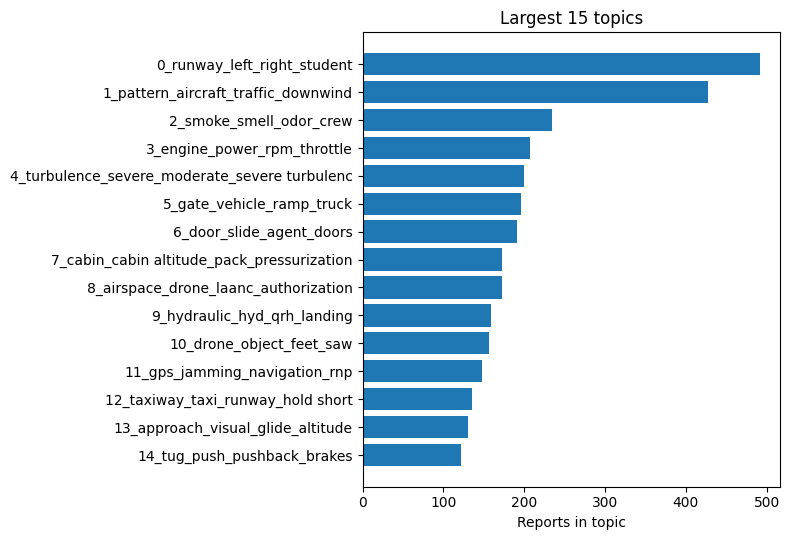

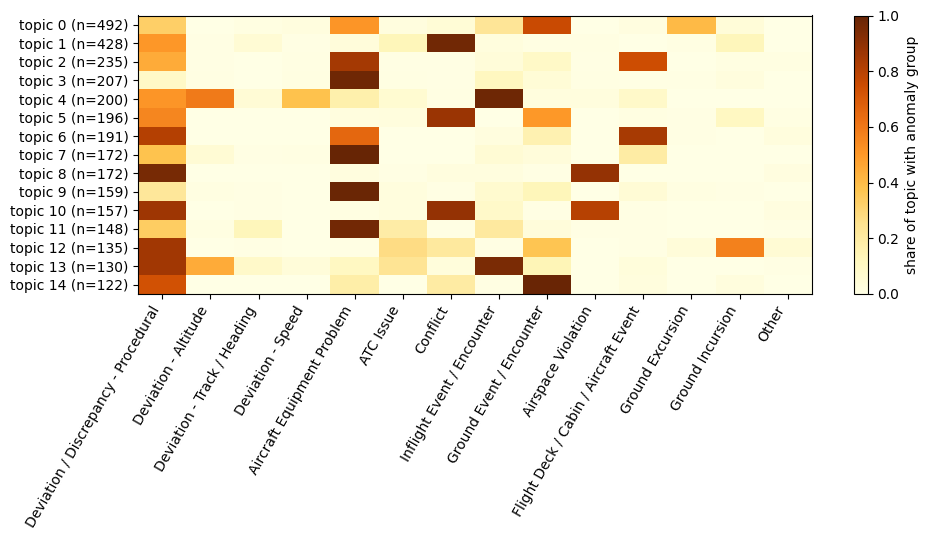

In [25]:
# make sure the inputs exist (builds them only if missing)
if "overview" not in globals():
    overview = topic_overview(model)
if "profile" not in globals():
    profile = topic_label_profile(topics, Y_tv, label_names)

plot_topic_sizes(overview, top=15)         # bar chart of the 15 largest themes
plot_topic_label_heatmap(profile, top=15)  # which anomaly groups each theme falls in

### 10. Ablations:

Remaining ablations (MiniLM vs bge-small, truncation vs chunking)

In [26]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from transformers import AutoTokenizer
from sentence_transformers import SentenceTransformer

# =============== Ablation 1: abbreviation expansion on/off (H3) ===============
# ---- compute
def tfidf_macro_f1(text_col, train_df, val_df, Y_train, Y_val, names):
    Xt, (Xv,), _ = build_tfidf(train_df[text_col], [val_df[text_col]])
    proba = train_ovr_logreg(Xt, Y_train).predict_proba(Xv)
    th = tune_thresholds(proba, Y_val)                              # same protocol as phase 5
    return evaluate_multilabel(proba, Y_val, th, names)[0]["macro_f1"]

def distilbert_macro_f1(text_col, train_df, val_df, Y_train, Y_val, names, seeds=(0, 1, 2), out_root="ablation"):
    tok = AutoTokenizer.from_pretrained(MODEL_NAME); tok.model_max_length = int(1e9)
    train_ds = NarrativeDataset(train_df[text_col], Y_train, tok)
    val_ds   = NarrativeDataset(val_df[text_col], Y_val, tok)
    pw, scores = compute_pos_weight(Y_train), []
    for s in seeds:
        tr = train_distilbert(s, train_ds, val_ds, pw, Y_train.shape[1], tok, f"{out_root}/{text_col}_{s}")
        proba = predict_proba(tr, val_ds)
        scores.append(evaluate_multilabel(proba, Y_val, tune_thresholds(proba, Y_val), names)[0]["macro_f1"])
        del tr; torch.cuda.empty_cache()
    return scores

def h3_effect(tfidf_plain, tfidf_exp, bert_plain, bert_exp):
    d_bert = np.array(bert_exp) - np.array(bert_plain)              # paired by seed
    return pd.DataFrame({"model": ["TF-IDF", "DistilBERT"],
                         "delta_macro_f1": [tfidf_exp - tfidf_plain, d_bert.mean()],
                         "seed_std": [0.0, d_bert.std(ddof=1)]}).round(4)

# ---- plot
def plot_abbrev_effect(effect):
    fig, ax = plt.subplots(figsize=(5, 3.8))
    ax.bar(effect["model"], effect["delta_macro_f1"], yerr=effect["seed_std"], capsize=6)
    ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("Δ macro-F1 (expanded − plain)")
    ax.set_title("Effect of abbreviation expansion"); plt.tight_layout(); plt.show()

# =============== Ablations 2 and 3: embedding model, truncation vs chunking (retrieval) ===============
# ---- build
def embed_with_model(model_name, train_texts, val_texts):
    m = SentenceTransformer(model_name)
    return embed_truncated(m, train_texts), embed_truncated(m, val_texts), m

def embed_chunked_pair(model, train_texts, val_texts, max_tokens=200):
    return embed_chunked(model, train_texts, max_tokens), embed_chunked(model, val_texts, max_tokens)

# ---- compute
def retrieval_variants(variants, k=10):
    # variants: {name: (emb_train, emb_val)} -> neighbour ids per method, using the phase 7/8 functions
    return {name: embedding_top_k(build_faiss_index(tr), va, k) for name, (tr, va) in variants.items()}

def paired_vs_baseline(per_query, baseline, variants, k=5):
    rows = []
    for v in variants:
        d, ci, p = paired_bootstrap_diff(per_query[(v, k)], per_query[(baseline, k)])
        rows.append({"variant": v, f"ΔP@{k} vs {baseline}": round(d, 3),
                     "95% CI": f"[{ci[0]:+.3f}, {ci[1]:+.3f}]", "one-sided p": round(p, 3)})
    return pd.DataFrame(rows)

def long_query_mask(texts, tokenizer, threshold=256):
    return np.array([len(tokenizer(t, add_special_tokens=False)["input_ids"]) > threshold for t in texts])

In [27]:
from sentence_transformers import SentenceTransformer

minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")   # the phase 7 model
print(minilm.max_seq_length, emb_train.shape)   # expect 256 and (n_train, 384)

ch_tr, ch_va = embed_chunked_pair(minilm, train_df["text"], val_df["text"])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

256 (6267, 384)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (329 > 256). Running this sequence through the model will result in indexing errors


Batches:   0%|          | 0/231 [00:00<?, ?it/s]

Batches:   0%|          | 0/48 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1 At 0.5
1,0.384494,0.365685,0.587415
2,0.311206,0.306762,0.645589
3,0.239481,0.291204,0.680070
4,0.219343,0.283011,0.682185


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (15 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1 At 0.5
1,0.374628,0.356542,0.578623
2,0.306466,0.305198,0.634930
3,0.255455,0.286440,0.665447
4,0.233965,0.281917,0.678279


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

        model  delta_macro_f1  seed_std
0      TF-IDF          0.0007    0.0000
1  DistilBERT         -0.0019    0.0008


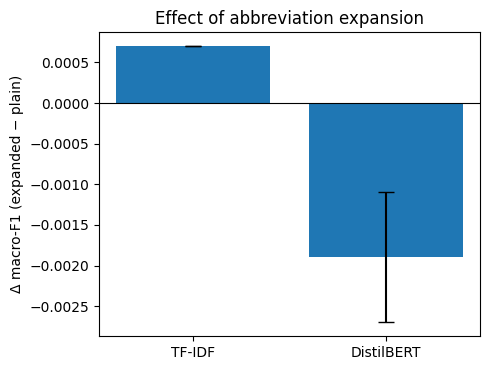

In [28]:
names = label_names

# --- Ablation 1 (H3). train_df / val_df need a "text_expanded" column; build_clean_table already makes it.
tf_plain = tfidf_macro_f1("text",          train_df, val_df, Y_train, Y_val, names)
tf_exp   = tfidf_macro_f1("text_expanded", train_df, val_df, Y_train, Y_val, names)
bert_plain = distilbert_macro_f1("text",          train_df, val_df, Y_train, Y_val, names)   # ~3 trainings each
bert_exp   = distilbert_macro_f1("text_expanded", train_df, val_df, Y_train, Y_val, names)
effect = h3_effect(tf_plain, tf_exp, bert_plain, bert_exp); print(effect); plot_abbrev_effect(effect)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (11 outputs left out)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (329 > 256). Running this sequence through the model will result in indexing errors


Batches:   0%|          | 0/231 [00:00<?, ?it/s]

Batches:   0%|          | 0/48 [00:00<?, ?it/s]

                  method    P@5      P@5 95% CI   P@10     P@10 95% CI
0     MiniLM (truncated)  0.642  [0.626, 0.659]  0.625  [0.611, 0.640]
1  bge-small (truncated)  0.637  [0.621, 0.653]  0.614  [0.599, 0.629]
2       MiniLM (chunked)  0.659  [0.643, 0.674]  0.637  [0.622, 0.651]


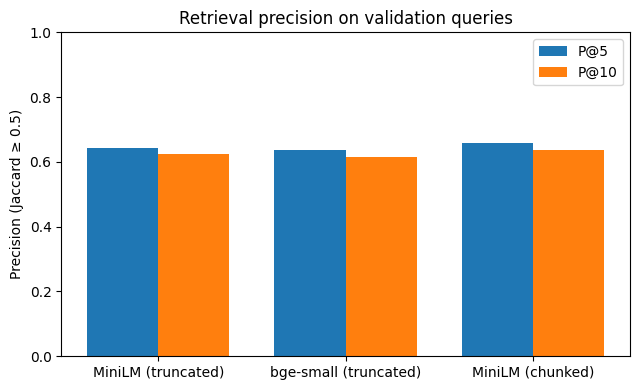

                 variant  ΔP@5 vs MiniLM (truncated)            95% CI  \
0  bge-small (truncated)                      -0.005  [-0.019, +0.008]   
1       MiniLM (chunked)                       0.016  [+0.004, +0.029]   

   one-sided p  
0        0.783  
1        0.005  
667 long queries
                  method    P@5      P@5 95% CI   P@10     P@10 95% CI
0     MiniLM (truncated)  0.628  [0.604, 0.652]  0.608  [0.585, 0.630]
1  bge-small (truncated)  0.626  [0.601, 0.650]  0.601  [0.580, 0.624]
2       MiniLM (chunked)  0.653  [0.631, 0.676]  0.634  [0.613, 0.655]
            variant  ΔP@5 vs MiniLM (truncated)            95% CI  one-sided p
0  MiniLM (chunked)                       0.024  [+0.006, +0.043]        0.006


In [29]:
# --- Ablations 2 and 3 (retrieval, same queries and metric as phase 8)
bge_tr, bge_va, _ = embed_with_model("BAAI/bge-small-en-v1.5", train_df["text"], val_df["text"])
from sentence_transformers import SentenceTransformer
minilm = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print(minilm.max_seq_length, emb_train.shape)    # expect 256 and (n_train, 384)

ch_tr, ch_va = embed_chunked_pair(minilm, train_df["text"], val_df["text"])
variants = {"MiniLM (truncated)": (emb_train, emb_val),
            "bge-small (truncated)": (bge_tr, bge_va),
            "MiniLM (chunked)": (ch_tr, ch_va)}
ids_by = retrieval_variants(variants)
table, per_query = build_retrieval_table(ids_by, Y_val, Y_train); print(table); plot_precision_bars(table)
print(paired_vs_baseline(per_query, "MiniLM (truncated)", ["bge-small (truncated)", "MiniLM (chunked)"]))

# chunking only matters for long narratives, so look at those separately
mask = long_query_mask(val_df["text"], minilm.tokenizer)
t_long, pq_long = build_retrieval_table({n: i[mask] for n, i in ids_by.items()}, Y_val[mask], Y_train)
print(f"{mask.sum()} long queries"); print(t_long)
print(paired_vs_baseline(pq_long, "MiniLM (truncated)", ["MiniLM (chunked)"]))

               method    P@5      P@5 95% CI   P@10     P@10 95% CI
0              Random  0.178  [0.168, 0.189]  0.178  [0.170, 0.186]
1     TF-IDF keywords  0.678  [0.662, 0.693]  0.655  [0.641, 0.669]
2  MiniLM (truncated)  0.642  [0.626, 0.659]  0.625  [0.611, 0.640]
3    MiniLM (chunked)  0.659  [0.643, 0.674]  0.637  [0.622, 0.651]


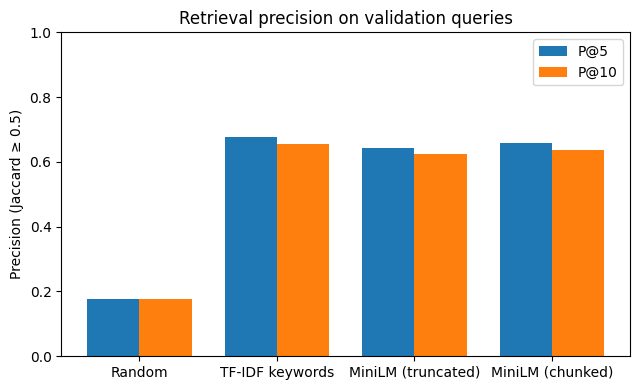

              variant  ΔP@5 vs TF-IDF keywords            95% CI  one-sided p
0  MiniLM (truncated)                   -0.035  [-0.049, -0.022]        1.000
1    MiniLM (chunked)                   -0.019  [-0.032, -0.005]        0.997
              variant  ΔP@10 vs TF-IDF keywords            95% CI  one-sided p
0  MiniLM (truncated)                    -0.030  [-0.040, -0.019]        1.000
1    MiniLM (chunked)                    -0.019  [-0.029, -0.008]        0.999
667 long queries
               method    P@5      P@5 95% CI   P@10     P@10 95% CI
0              Random  0.176  [0.161, 0.192]  0.180  [0.168, 0.191]
1     TF-IDF keywords  0.680  [0.656, 0.702]  0.653  [0.631, 0.674]
2  MiniLM (truncated)  0.628  [0.604, 0.652]  0.608  [0.585, 0.630]
3    MiniLM (chunked)  0.653  [0.631, 0.676]  0.634  [0.613, 0.655]
              variant  ΔP@5 vs TF-IDF keywords            95% CI  one-sided p
0  MiniLM (truncated)                   -0.051  [-0.072, -0.031]        1.000
1    MiniLM (chu

In [30]:
k = 10
ids_h2 = {
    "Random":             random_top_k(len(val_df), len(train_df), k),
    "TF-IDF keywords":    tfidf_top_k(train_df["text"], val_df["text"], k),
    "MiniLM (truncated)": embedding_top_k(build_faiss_index(emb_trunc[train_i]), emb_trunc[val_i], k),
    "MiniLM (chunked)":   embedding_top_k(build_faiss_index(emb_chunk[train_i]), emb_chunk[val_i], k),
}

# precision@5 / @10 with 95% bootstrap intervals (same proxy and queries as the earlier ablation table)
table, per_query = build_retrieval_table(ids_h2, Y_val, Y_train)
print(table); plot_precision_bars(table)

# H2 itself: paired difference against TF-IDF, query by query
challengers = ["MiniLM (truncated)", "MiniLM (chunked)"]
print(paired_vs_baseline(per_query, "TF-IDF keywords", challengers, k=5))
print(paired_vs_baseline(per_query, "TF-IDF keywords", challengers, k=10))

# long narratives only (over 256 word-pieces), where chunking matters
mask = long_query_mask(val_df["text"], minilm.tokenizer)
t_long, pq_long = build_retrieval_table({n: i[mask] for n, i in ids_h2.items()}, Y_val[mask], Y_train)
print(f"{mask.sum()} long queries"); print(t_long)
print(paired_vs_baseline(pq_long, "TF-IDF keywords", challengers, k=5))

In [31]:
n_rows = make_rubric_sheet(val_df, train_df,
                           {m: ids_h2[m] for m in ("TF-IDF keywords", "MiniLM (chunked)")}, Y_val)
print(n_rows, "candidate pairs to score")   # open rubric_sheet.csv and fill the score column: 2 same issue, 1 related, 0 unrelated
# after scoring:  print(score_rubric_sheet())

262 candidate pairs to score


### 11. Error Analysis

In [32]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---------- 1. predictions ----------
def predict_labels(proba, thresholds):
    th = list(thresholds.values()) if isinstance(thresholds, dict) else thresholds
    return (proba >= np.asarray(th)).astype(int)

# ---------- 2. one row per report: what was missed, what was added ----------
def build_error_table(Y, pred, names, val_df):
    rows = []
    for i in range(len(Y)):
        t, p = set(np.where(Y[i] == 1)[0]), set(np.where(pred[i] == 1)[0])
        rows.append({"idx": i, "true": [names[j] for j in sorted(t)], "pred": [names[j] for j in sorted(p)],
                     "missed": [names[j] for j in sorted(t - p)], "extra": [names[j] for j in sorted(p - t)],
                     "jaccard": len(t & p) / max(len(t | p), 1), "n_true": len(t),
                     "n_words": len(val_df["text"].iloc[i].split())})
    err = pd.DataFrame(rows)
    err["exact"] = (err["missed"].str.len() == 0) & (err["extra"].str.len() == 0)
    return err

# ---------- 3. per-group false positives / false negatives ----------
def group_error_counts(Y, pred, names):
    tp, fp, fn = ((Y == 1) & (pred == 1)).sum(0), ((Y == 0) & (pred == 1)).sum(0), ((Y == 1) & (pred == 0)).sum(0)
    out = pd.DataFrame({"group": names, "support": Y.sum(0), "FP": fp, "FN": fn})
    out["precision"] = (tp / np.maximum(tp + fp, 1)).round(3)
    out["recall"] = (tp / np.maximum(tp + fn, 1)).round(3)
    return out.sort_values("support", ascending=False).reset_index(drop=True)

# ---------- 4. which label gets confused for which (missed A, predicted B in the same report) ----------
def confused_pairs(err, top=10):
    pairs = {}
    for _, r in err.iterrows():
        for a in r["missed"]:
            for b in r["extra"]:
                pairs[(a, b)] = pairs.get((a, b), 0) + 1
    return (pd.DataFrame([(a, b, n) for (a, b), n in pairs.items()], columns=["missed", "predicted_instead", "count"])
            .sort_values("count", ascending=False).head(top).reset_index(drop=True))

# ---------- 5. error rate by a numeric column (used for length and for number of labels) ----------
def rate_by_bin(err, col, bins, labels):
    b = pd.cut(err[col], bins=bins, labels=labels, right=True)
    return err.groupby(b, observed=True).agg(reports=("exact", "size"), exact_match=("exact", "mean"),
                                             mean_jaccard=("jaccard", "mean")).round(3).reset_index()

# ---------- 6. a sample of errors for manual reading ----------
def sample_errors(err, val_df, n=20, seed=42):
    bad = err[~err["exact"]].copy()
    bad["kind"] = np.where(bad["extra"].str.len() == 0, "missed only",
                   np.where(bad["missed"].str.len() == 0, "extra only", "both"))
    per = max(n // 3, 1)
    parts = [g.sample(min(per, len(g)), random_state=seed) for _, g in bad.groupby("kind")]
    s = pd.concat(parts).head(n).copy()
    s["text"] = [val_df["text"].iloc[i][:700] for i in s["idx"]]
    s["reason"] = ""       # fill by hand: label_noise, ambiguous_text, truncated, rare_group, model_error
    return s[["idx", "kind", "n_words", "true", "missed", "extra", "text", "reason"]].reset_index(drop=True)

# ---------- 7. count the reasons after you tag them ----------
def summarise_reasons(sheet):
    return sheet["reason"].value_counts().rename_axis("reason").reset_index(name="count")

# ---------- plots (separate from the computation) ----------
def plot_group_errors(counts):
    x = np.arange(len(counts)); fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(x - 0.2, counts["FN"], 0.4, label="missed (FN)"); ax.bar(x + 0.2, counts["FP"], 0.4, label="added (FP)")
    ax.set_xticks(x); ax.set_xticklabels(counts["group"], rotation=60, ha="right")
    ax.set_ylabel("reports"); ax.set_title("Errors per anomaly group"); ax.legend(); plt.tight_layout(); plt.show()

def plot_rate_by_bin(tab, col_label, title):
    fig, ax = plt.subplots(figsize=(5.5, 3.8))
    ax.bar(tab.iloc[:, 0].astype(str), tab["exact_match"])
    for i, (n, v) in enumerate(zip(tab["reports"], tab["exact_match"])): ax.text(i, v + 0.01, f"n={n}", ha="center", fontsize=8)
    ax.set_xlabel(col_label); ax.set_ylabel("exact-match rate"); ax.set_title(title); plt.tight_layout(); plt.show()

exact match: 0.313 | mean Jaccard: 0.667
                                   group  support   FP  FN  precision  recall
0   Deviation / Discrepancy - Procedural      695  389  95      0.607   0.863
1             Aircraft Equipment Problem      604   34  81      0.939   0.866
2             Inflight Event / Encounter      361  131  36      0.713   0.900
3                               Conflict      336   15  42      0.951   0.875
4               Ground Event / Encounter      250   66  75      0.726   0.700
5                              ATC Issue      197   56  62      0.707   0.685
6                   Deviation - Altitude      114  104  18      0.480   0.842
7   Flight Deck / Cabin / Aircraft Event       96   12  23      0.859   0.760
8                     Airspace Violation       74   18  10      0.780   0.865
9                       Ground Incursion       67  103   9      0.360   0.866
10           Deviation - Track / Heading       58   33  27      0.484   0.534
11                     

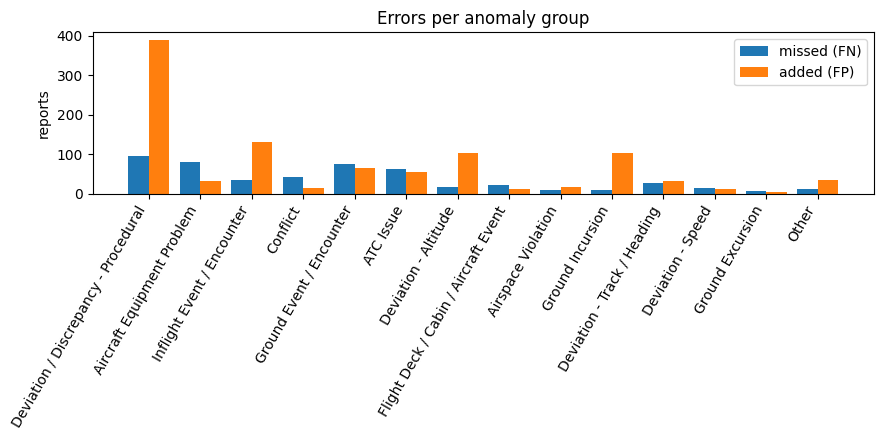

                                 missed                     predicted_instead  \
0                             ATC Issue  Deviation / Discrepancy - Procedural   
1            Aircraft Equipment Problem  Deviation / Discrepancy - Procedural   
2              Ground Event / Encounter  Deviation / Discrepancy - Procedural   
3            Aircraft Equipment Problem            Inflight Event / Encounter   
4                              Conflict  Deviation / Discrepancy - Procedural   
5                              Conflict            Inflight Event / Encounter   
6  Deviation / Discrepancy - Procedural            Inflight Event / Encounter   
7            Aircraft Equipment Problem                  Deviation - Altitude   
8            Inflight Event / Encounter  Deviation / Discrepancy - Procedural   
9                             ATC Issue                  Deviation - Altitude   

   count  
0     29  
1     21  
2     21  
3     20  
4     13  
5     12  
6     12  
7     12  
8     12 

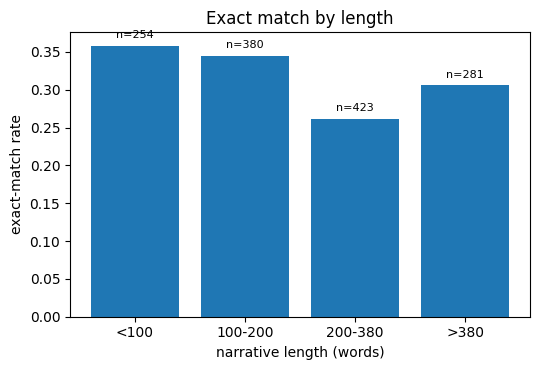

In [33]:
seed = 2
proba = val_probs[seed] if "val_probs" in globals() else np.load(f"{MODELS_DIR}/val_probs_seed{seed}.npy")
th = tune_thresholds(proba, Y_val)                       # same thresholds as phase 6
pred = predict_labels(proba, th)

err = build_error_table(Y_val, pred, label_names, val_df)
print("exact match:", err["exact"].mean().round(3), "| mean Jaccard:", err["jaccard"].mean().round(3))

counts = group_error_counts(Y_val, pred, label_names); print(counts); plot_group_errors(counts)
print(confused_pairs(err))

by_len = rate_by_bin(err, "n_words", [0, 100, 200, 380, 10**5], ["<100", "100-200", "200-380", ">380"])
by_n   = rate_by_bin(err, "n_true", [0, 1, 2, 20], ["1 label", "2 labels", "3+ labels"])
print(by_len); print(by_n); plot_rate_by_bin(by_len, "narrative length (words)", "Exact match by length")

sheet = sample_errors(err, val_df, n=20); sheet.to_csv("error_sheet.csv", index=False)
# open error_sheet.csv, read each text, fill "reason" with one of:
#   label_noise, ambiguous_text, truncated, rare_group, model_error
# then: print(summarise_reasons(pd.read_csv("error_sheet.csv")))

Summarising the reasons for the errors

In [34]:
print(summarise_reasons(pd.read_csv("error_sheet.csv")))

Empty DataFrame
Columns: [reason, count]
Index: []


### 12. Test Run

In [35]:
import json, os
import numpy as np, pandas as pd, torch
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

TEST_OUT = f"{os.path.dirname(MODELS_DIR)}/test_results.json"

# ---------- 0. guard: the test set is used once ----------
def guard_single_run(path):
    if os.path.exists(path):
        raise RuntimeError(f"{path} exists: the test set has already been used. Do not re-run.")

# ---------- 1. TF-IDF baseline (fit on train, thresholds from val, scored on test) ----------
def test_tfidf(df, Y, train_i, val_i, test_i, col="text"):
    Xtr, (Xva, Xte), _ = build_tfidf(df[col].iloc[train_i], [df[col].iloc[val_i], df[col].iloc[test_i]])
    clf = train_ovr_logreg(Xtr, Y.values[train_i])
    th = tune_thresholds(clf.predict_proba(Xva), Y.values[val_i])
    pt = clf.predict_proba(Xte)
    metrics, per = evaluate_multilabel(pt, Y.values[test_i], th, Y.columns)
    return metrics, per

# ---------- 2. DistilBERT: saved checkpoints, val-tuned thresholds applied unchanged ----------
def predict_saved_distilbert(seed, ds, tokenizer):
    m = AutoModelForSequenceClassification.from_pretrained(f"{MODELS_DIR}/distilbert_seed{seed}")
    args = TrainingArguments(output_dir="/tmp/eval_tmp", per_device_eval_batch_size=32,
                             report_to="none", remove_unused_columns=False)
    tr = Trainer(model=m, args=args, data_collator=make_collator(tokenizer))
    p = 1 / (1 + np.exp(-tr.predict(ds).predictions))
    del tr, m; torch.cuda.empty_cache()
    return p

def test_distilbert(df, Y, val_i, test_i, tokenizer, seeds=(1, 2, 3)):
    test_ds = NarrativeDataset(df["text"].iloc[test_i], Y.values[test_i], tokenizer)
    res, per = {}, {}
    for s in seeds:
        th = tune_thresholds(np.load(f"{MODELS_DIR}/val_probs_seed{s}.npy"), Y.values[val_i])
        res[s], per[s] = evaluate_multilabel(predict_saved_distilbert(s, test_ds, tokenizer),
                                             Y.values[test_i], th, Y.columns)
    return res, per

# ---------- 3. retrieval: queries = test, index = train (same as validation) ----------
def test_retrieval(df, Y, train_i, test_i, emb_trunc, emb_chunk, mini_tok, ks=(5, 10)):
    k = max(ks)
    q_txt, i_txt = df["text"].iloc[test_i], df["text"].iloc[train_i]
    Yq, Yi = Y.values[test_i], Y.values[train_i]
    ids = {"Random": random_top_k(len(test_i), len(train_i), k),
           "TF-IDF keywords": tfidf_top_k(i_txt, q_txt, k),
           "MiniLM truncated": embedding_top_k(build_faiss_index(emb_trunc[train_i]), emb_trunc[test_i], k),
           "MiniLM chunked": embedding_top_k(build_faiss_index(emb_chunk[train_i]), emb_chunk[test_i], k)}
    pq = {m: {kk: precision_at_k(relevance_hits(Yq, Yi, v), kk) for kk in ks} for m, v in ids.items()}
    long_m = np.asarray(long_query_mask(list(q_txt), mini_tok), dtype=bool)
    rows = []
    for m in pq:
        r = {"method": m}
        for kk in ks:
            mu, lo, hi = mean_ci(pq[m][kk]); r[f"P@{kk}"], r[f"P@{kk}_lo"], r[f"P@{kk}_hi"] = mu, lo, hi
        r["P@5_long"] = pq[m][5][long_m].mean()
        rows.append(r)
    base, paired = "TF-IDF keywords", []
    for m in ("MiniLM truncated", "MiniLM chunked"):
        for kk in ks:
            d, (lo, hi), _ = paired_bootstrap_diff(pq[m][kk], pq[base][kk])
            paired.append({"method": m, "metric": f"dP@{kk} vs TF-IDF", "diff": d, "lo": lo, "hi": hi})
        d, (lo, hi), _ = paired_bootstrap_diff(pq[m][5][long_m], pq[base][5][long_m])
        paired.append({"method": m, "metric": "dP@5 long vs TF-IDF", "diff": d, "lo": lo, "hi": hi})
    return pd.DataFrame(rows), pd.DataFrame(paired), int(long_m.sum())

# ---------- 4. themes: refit on train+val as before, then assign test reports ----------
def test_topics(df, Y, train_i, val_i, test_i, emb_trunc, min_cluster_size=30):
    tv = list(df["text"].iloc[train_i]) + list(df["text"].iloc[val_i])
    emb_tv = np.vstack([emb_trunc[train_i], emb_trunc[val_i]])
    tm, tv_topics = build_topic_model(tv, emb_tv, min_cluster_size=min_cluster_size)
    te_topics, _ = tm.transform(list(df["text"].iloc[test_i]), embeddings=emb_trunc[test_i])
    te_topics = np.array(te_topics)
    return {"n_themes": int(len(set(tv_topics)) - (-1 in tv_topics)),
            "outlier_share_trainval": outlier_share(tv_topics),
            "outlier_share_test": outlier_share(te_topics),
            "themes_used_by_test": int(len(set(te_topics) - {-1}))}

# ---------- 5. plots (separate from compute) ----------
def plot_classifier_val_vs_test(scores):          # {name: (val_macro_f1, test_macro_f1)}
    import matplotlib.pyplot as plt
    x, w = np.arange(len(scores)), 0.38
    plt.bar(x - w/2, [v[0] for v in scores.values()], w, label="validation")
    plt.bar(x + w/2, [v[1] for v in scores.values()], w, label="test")
    plt.xticks(x, scores.keys()); plt.ylabel("macro-F1"); plt.legend(); plt.tight_layout(); plt.show()

def plot_test_retrieval(table, ks=(5, 10)):
    import matplotlib.pyplot as plt
    x, w = np.arange(len(table)), 0.38
    for j, kk in enumerate(ks):
        plt.bar(x + (j - 0.5) * w, table[f"P@{kk}"], w,
                yerr=[table[f"P@{kk}"] - table[f"P@{kk}_lo"], table[f"P@{kk}_hi"] - table[f"P@{kk}"]],
                capsize=3, label=f"P@{kk}")
    plt.xticks(x, table["method"], rotation=15, ha="right"); plt.ylabel("precision (test)")
    plt.legend(); plt.tight_layout(); plt.show()

In [36]:
# ---------- RUN ONCE ----------
from sentence_transformers import SentenceTransformer
guard_single_run(TEST_OUT)
mini_tok = SentenceTransformer("all-MiniLM-L6-v2").tokenizer

tf_m, tf_per = test_tfidf(df, Y, train_i, val_i, test_i)
bt_m, bt_per = test_distilbert(df, Y, val_i, test_i, tokenizer)
bt_mean, bt_sd = summarise_seeds(bt_m)
ret_tbl, ret_paired, n_long = test_retrieval(df, Y, train_i, test_i, emb_trunc, emb_chunk, mini_tok)
themes = test_topics(df, Y, train_i, val_i, test_i, emb_trunc)

print(f"TF-IDF   macro-F1 {tf_m['macro_f1']:.3f}  micro-F1 {tf_m['micro_f1']:.3f}")
print(f"DistilBERT macro-F1 {bt_mean:.3f} ± {bt_sd:.3f}  micro-F1 {np.mean([r['micro_f1'] for r in bt_m.values()]):.3f}")
display(ret_tbl.round(3)); display(ret_paired.round(3)); print("long queries:", n_long); print(themes)

plot_classifier_val_vs_test({"TF-IDF": (res["text"]["macro_f1"], tf_m["macro_f1"]),
                             "DistilBERT": (summarise_seeds(bert_res)[0], bt_mean)})
plot_test_retrieval(ret_tbl)

json.dump({"tfidf": tf_m, "distilbert": {str(s): r for s, r in bt_m.items()},
           "retrieval": ret_tbl.to_dict("records"), "paired": ret_paired.to_dict("records"),
           "n_long": n_long, "themes": themes}, open(TEST_OUT, "w"), default=float, indent=2)

RuntimeError: /content/drive/MyDrive/asrs-copilot/test_results.json exists: the test set has already been used. Do not re-run.

### 13. Hybrid retrieval (exploratory)

In [37]:
# ---------- 1. similarity matrices (queries x train) ----------
def tfidf_scores(train_texts, query_texts):
    Xt, (Xq,), _ = build_tfidf(train_texts, [query_texts])
    return (Xq @ Xt.T).toarray().astype("float32")                  # cosine, as in tfidf_top_k

def embedding_scores(emb_train, emb_query):
    return (emb_query @ emb_train.T).astype("float32")              # cosine, vectors are normalised

def top_ids(S, k=10):
    part = np.argpartition(-S, k, axis=1)[:, :k]
    return np.take_along_axis(part, np.argsort(-np.take_along_axis(S, part, 1), axis=1), 1)

# ---------- 2. hybrids (one function per technique) ----------
def rrf_top_k(S_a, S_b, k=10, depth=50, c=60):
    ra, rb = top_ids(S_a, depth), top_ids(S_b, depth)               # reciprocal rank fusion
    out = np.zeros((len(S_a), k), dtype=int)
    for q in range(len(S_a)):
        score = {}
        for ranks in (ra[q], rb[q]):
            for r, j in enumerate(ranks):
                score[int(j)] = score.get(int(j), 0.0) + 1.0 / (c + r + 1)
        out[q] = sorted(score, key=score.get, reverse=True)[:k]
    return out

def zscore_fusion_top_k(S_a, S_b, alpha=0.5, k=10):
    z = lambda S: (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)
    return top_ids(alpha * z(S_a) + (1 - alpha) * z(S_b), k)        # weighted sum of per-query z-scores

# ---------- 3. evaluation (validation only) ----------
def hybrid_paired_table(per_query, variants, baselines, ks=(5, 10)):
    rows = []
    for v in variants:
        for b in baselines:
            for k in ks:
                d, (lo, hi), _ = paired_bootstrap_diff(per_query[(v, k)], per_query[(b, k)])
                rows.append({"hybrid": v, "vs": b, "metric": f"dP@{k}", "diff": round(d, 3),
                             "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
    return pd.DataFrame(rows)

,method,P@5,P@5 95% CI,P@10,P@10 95% CI
0,TF-IDF,0.678,"[0.662, 0.693]",0.655,"[0.641, 0.669]"
1,MiniLM chunked,0.659,"[0.643, 0.674]",0.637,"[0.622, 0.651]"
2,Hybrid RRF,0.690,"[0.675, 0.704]",0.667,"[0.652, 0.682]"
3,Hybrid z-score,0.700,"[0.684, 0.715]",0.674,"[0.660, 0.688]"


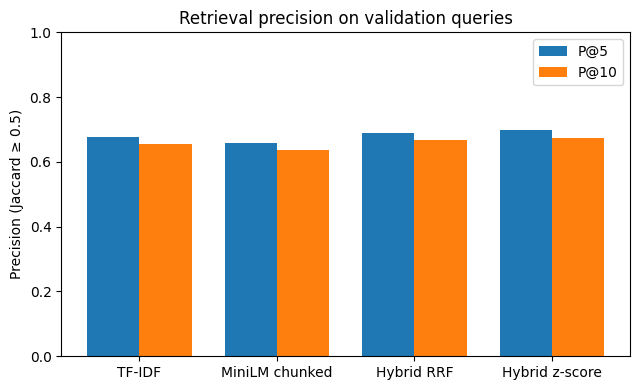

,hybrid,vs,metric,diff,95% CI
0,Hybrid RRF,TF-IDF,dP@5,0.012,"[0.001, 0.023]"
1,Hybrid RRF,TF-IDF,dP@10,0.012,"[0.004, 0.020]"
2,Hybrid RRF,MiniLM chunked,dP@5,0.031,"[0.021, 0.041]"
3,Hybrid RRF,MiniLM chunked,dP@10,0.030,"[0.023, 0.038]"
4,Hybrid z-score,TF-IDF,dP@5,0.022,"[0.014, 0.030]"
5,Hybrid z-score,TF-IDF,dP@10,0.019,"[0.014, 0.025]"
6,Hybrid z-score,MiniLM chunked,dP@5,0.041,"[0.030, 0.053]"
7,Hybrid z-score,MiniLM chunked,dP@10,0.038,"[0.029, 0.046]"


In [38]:
# ---------- run (validation) ----------
S_tf = tfidf_scores(df["text"].iloc[train_i], df["text"].iloc[val_i])
S_em = embedding_scores(emb_chunk[train_i], emb_chunk[val_i])
ids_by_method = {"TF-IDF": top_ids(S_tf), "MiniLM chunked": top_ids(S_em),
                 "Hybrid RRF": rrf_top_k(S_tf, S_em), "Hybrid z-score": zscore_fusion_top_k(S_tf, S_em)}
table, per_q = build_retrieval_table(ids_by_method, Y.values[val_i], Y.values[train_i])
display(table); plot_precision_bars(table)
display(hybrid_paired_table(per_q, ["Hybrid RRF", "Hybrid z-score"], ["TF-IDF", "MiniLM chunked"]))

### 14. Manual retrieval rubric (30 queries)

The proxy counts a neighbour as relevant when anomaly groups overlap, which may favour keyword matching. This rubric judges relevance by meaning instead.

- **Sample:** 30 validation queries drawn with a fixed seed. Candidates are the top 5 from TF-IDF, MiniLM (chunked) and the RRF hybrid, pooled and shuffled so the scorer cannot tell which method found them.
- **Scoring:** 2 = same safety issue, 1 = related, 0 = unrelated. Scores are entered before opening the key file.
- **Analysis:** mean score per method, and paired bootstrap differences against TF-IDF.
- **Limits:** one scorer and only 30 queries, so intervals are wide and there is no inter-rater check.

In [39]:
RUB_DIR = "/content/drive/MyDrive/asrs-copilot/rubric"
import os; os.makedirs(RUB_DIR, exist_ok=True)
SHEET, KEY = f"{RUB_DIR}/rubric_sheet.csv", f"{RUB_DIR}/rubric_key.csv"

In [40]:
def rubric_full_text(sheet_path=SHEET, n=30, seed=42):
    sheet = pd.read_csv(sheet_path)
    rng = np.random.default_rng(seed)                       # same draw as make_rubric_sheet
    qs = rng.choice(np.where(Y.values[val_i].sum(1) > 0)[0], size=n, replace=False)
    q_text = {qi: df["text"].iloc[val_i[q]] for qi, q in enumerate(qs)}
    for qi, g in sheet.groupby("qid"):                      # sanity check against the sheet
        assert q_text[qi][:600] == g["query"].iloc[0], f"query {qi} does not match the sheet"
    return q_text

def score_with_buttons_v2(sheet_path=SHEET):
    import ipywidgets as w, html
    from IPython.display import display
    from google.colab import output; output.enable_custom_widget_manager()
    q_text = rubric_full_text(sheet_path)
    sheet = pd.read_csv(sheet_path)
    todo = list(sheet.index[sheet["score"].isna()])
    st, view, head = {"k": 0}, w.HTML(), w.HTML()

    def render():
        k = st["k"]
        if k >= len(todo):
            head.value, view.value = "<b>&nbsp;All rows scored.</b>", ""; return
        r = sheet.loc[todo[k]]
        cand = df["text"].iloc[train_i[int(r.candidate_id)]]
        head.value = f"<b>&nbsp;&nbsp;{k + 1}/{len(todo)}</b>"
        view.value = ("<div style='font-family:monospace;white-space:pre-wrap;line-height:1.4'>"
                      "<b>QUERY</b>\n" + html.escape(q_text[int(r.qid)]) +
                      "\n\n<b>CANDIDATE</b>\n" + html.escape(cand) + "</div>")

    def rate(score):
        def handler(_):
            if st["k"] < len(todo):
                sheet.loc[todo[st["k"]], "score"] = score
                sheet.to_csv(sheet_path, index=False); st["k"] += 1; render()
        return handler

    def back(_):
        st["k"] = max(0, st["k"] - 1); render()

    btns = [w.Button(description=d, layout=w.Layout(width="130px")) for d in ("0  unrelated", "1  related", "2  same issue")]
    for b, s in zip(btns, (0, 1, 2)):
        b.on_click(rate(s))
    undo = w.Button(description="← back", layout=w.Layout(width="90px")); undo.on_click(back)
    display(w.VBox([w.HBox(btns + [undo, head]), view])); render()

In [41]:
for f in (SHEET, KEY):
    if os.path.exists(f): os.remove(f)
sub = {m: ids_by_method[m] for m in ("TF-IDF", "MiniLM chunked", "Hybrid z-score")}
n = make_rubric_sheet(df.iloc[val_i].reset_index(drop=True), df.iloc[train_i].reset_index(drop=True),
                      sub, Y.values[val_i], n=30, k=3, sheet_path=SHEET, key_path=KEY)
print(n, "rows")

171 rows


In [42]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [43]:
score_with_buttons_v2()

In [44]:
LLM_PATH = f"{RUB_DIR}/rubric_sheet_llm.csv"
HUMAN_PATH = f"{RUB_DIR}/rubric_sample_human.csv"

def sample_rows_for_human(llm_path=LLM_PATH, human_path=HUMAN_PATH, n=30, seed=7):
    if os.path.exists(human_path):
        return f"{human_path} already exists, not overwriting"          # protects scores you've entered
    s = pd.read_csv(llm_path)
    pick = s.sample(n=n, random_state=seed).copy()
    pick["score"] = np.nan                                              # my scores are removed from this file
    pick.to_csv(human_path, index=False)
    return f"{len(pick)} rows written to {human_path}"

def score_sheet_buttons(path=HUMAN_PATH):
    import ipywidgets as w, html
    from IPython.display import display
    from google.colab import output; output.enable_custom_widget_manager()
    sheet = pd.read_csv(path)
    todo = list(sheet.index[sheet["score"].isna()])
    st, view, head = {"k": 0}, w.HTML(), w.HTML()

    def render():
        k = st["k"]
        if k >= len(todo):
            head.value, view.value = "<b>&nbsp;All rows scored.</b>", ""; return
        r = sheet.loc[todo[k]]
        head.value = f"<b>&nbsp;&nbsp;{k + 1}/{len(todo)}</b>"
        view.value = ("<div style='font-family:monospace;white-space:pre-wrap;line-height:1.4'>"
                      "<b>QUERY</b>\n" + html.escape(str(r["query"])) +
                      "\n\n<b>CANDIDATE</b>\n" + html.escape(str(r["candidate"])) + "</div>")

    def rate(score):
        def handler(_):
            if st["k"] < len(todo):
                sheet.loc[todo[st["k"]], "score"] = score
                sheet.to_csv(path, index=False); st["k"] += 1; render()
        return handler

    def back(_):
        st["k"] = max(0, st["k"] - 1); render()

    btns = [w.Button(description=d, layout=w.Layout(width="130px")) for d in ("0  unrelated", "1  related", "2  same issue")]
    for b, s in zip(btns, (0, 1, 2)):
        b.on_click(rate(s))
    undo = w.Button(description="← back", layout=w.Layout(width="90px")); undo.on_click(back)
    display(w.VBox([w.HBox(btns + [undo, head]), view])); render()

def judge_agreement(llm_path=LLM_PATH, human_path=HUMAN_PATH):
    from sklearn.metrics import cohen_kappa_score
    a, b = pd.read_csv(llm_path), pd.read_csv(human_path).dropna(subset=["score"])
    m = b.merge(a[["qid", "candidate_id", "score"]], on=["qid", "candidate_id"], suffixes=("_human", "_llm"))
    return {"n": len(m), "exact_agreement": round((m.score_human == m.score_llm).mean(), 3),
            "weighted_kappa": round(cohen_kappa_score(m.score_human, m.score_llm, weights="quadratic"), 3),
            "human_mean": round(m.score_human.mean(), 2), "llm_mean": round(m.score_llm.mean(), 2)}

In [45]:
print(sample_rows_for_human())

/content/drive/MyDrive/asrs-copilot/rubric/rubric_sample_human.csv already exists, not overwriting


In [46]:
score_sheet_buttons()

In [47]:
print(judge_agreement())

{'n': 30, 'exact_agreement': np.float64(0.433), 'weighted_kappa': np.float64(0.315), 'human_mean': np.float64(1.33), 'llm_mean': np.float64(0.83)}


In [48]:
def agreement_breakdown(llm_path=LLM_PATH, human_path=HUMAN_PATH):
    from scipy.stats import spearmanr
    from sklearn.metrics import cohen_kappa_score
    a, b = pd.read_csv(llm_path), pd.read_csv(human_path).dropna(subset=["score"])
    m = b.merge(a[["qid", "candidate_id", "score"]], on=["qid", "candidate_id"], suffixes=("_human", "_llm"))
    out = {"spearman": round(spearmanr(m.score_human, m.score_llm)[0], 3)}
    for t in (1, 2):                                                     # binary views of the same scores
        h, l = (m.score_human >= t).astype(int), (m.score_llm >= t).astype(int)
        out[f"kappa, relevant = score >= {t}"] = round(cohen_kappa_score(h, l), 3)
        out[f"agree, relevant = score >= {t}"] = round((h == l).mean(), 3)
    print(pd.crosstab(m.score_human, m.score_llm, rownames=["human"], colnames=["claude"]))
    return out

print(agreement_breakdown())

claude  0  1  2
human          
0.0     4  0  0
1.0     5  4  3
2.0     4  5  5
{'spearman': np.float64(0.369), 'kappa, relevant = score >= 1': np.float64(0.335), 'agree, relevant = score >= 1': np.float64(0.7), 'kappa, relevant = score >= 2': np.float64(0.174), 'agree, relevant = score >= 2': np.float64(0.6)}


In [49]:
def score_rubric_means(sheet_path, key_path):
    sheet, key = pd.read_csv(sheet_path), pd.read_csv(key_path)       # key: which method found each candidate
    m = key.merge(sheet[["qid", "candidate_id", "score"]], on=["qid", "candidate_id"])
    return m.groupby("method")["score"].agg(["mean", "count"]).round(3)

def rubric_per_query(sheet_path, key_path):
    sheet, key = pd.read_csv(sheet_path), pd.read_csv(key_path)
    m = key.merge(sheet[["qid", "candidate_id", "score"]], on=["qid", "candidate_id"])
    return m.groupby(["method", "qid"])["score"].mean().unstack(0)    # one row per query, one column per method

def rubric_paired(pq, base):
    rows = []
    for m in pq.columns.drop(base):
        d, (lo, hi), _ = paired_bootstrap_diff(pq[m].values, pq[base].values)
        rows.append({"method": m, "vs": base, "mean diff": round(d, 3), "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
    return pd.DataFrame(rows)

print(score_rubric_means(LLM_PATH, KEY))
pq = rubric_per_query(LLM_PATH, KEY)
display(rubric_paired(pq, base="TF-IDF"))
display(rubric_paired(pq, base="MiniLM chunked"))

                 mean  count
method                      
Hybrid z-score  1.402     87
MiniLM chunked  1.111     90
TF-IDF          1.378     90


,method,vs,mean diff,95% CI
0,Hybrid z-score,TF-IDF,0.039,"[-0.078, 0.150]"
1,MiniLM chunked,TF-IDF,-0.267,"[-0.456, -0.089]"


,method,vs,mean diff,95% CI
0,Hybrid z-score,MiniLM chunked,0.306,"[0.144, 0.478]"
1,TF-IDF,MiniLM chunked,0.267,"[0.089, 0.456]"


### 15. Gradio Demo

Run the cells in order. Cells A to G only define things; the last cell builds the demo and launches it. The demo has a light and a dark mode, switched with the button at the top right.

In [96]:
!pip -q install gradio

**A. Palettes (dark `D` and light `L`), fonts, CSS, hero** (edit the header text and pills in `HERO`, the headline numbers in `RESULTS`)

In [97]:
import html, inspect, random
from types import SimpleNamespace
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, gradio as gr
from transformers import AutoModelForSequenceClassification

TITLE = "ASRS Copilot"
# palette shared with the project deck: dark values and light values
D = dict(page_a="#1B1E23", page_b="#2B2F36", panel="#2B2F36", chip="#343942", edge="#3A3F48", ink="#F2EFE8",
         soft="#D6D2C8", muted="#A6A296", accent_ink="#F5C518", input="#1B1E23", track="#3A3F48", off="#5F5B53")
L = dict(page_a="#FBF8F0", page_b="#F0EBDD", panel="#FFFFFF", chip="#F3EFE4", edge="#E3DDCE", ink="#1B1E23",
         soft="#46433B", muted="#6B665A", accent_ink="#8A5A00", input="#FBF9F4", track="#E8E2D2", off="#B9B3A3")
YELLOW, ORANGE = "#F5C518", "#FF7A3D"


def page_gradient(p):
    return (f"radial-gradient(900px 520px at 92% -6%, rgba(245,197,24,.17), transparent 62%), "
            f"radial-gradient(820px 620px at -6% 104%, rgba(255,122,61,.15), transparent 60%), "
            f"linear-gradient(160deg, {p['page_a']} 0%, {p['page_b']} 100%)")


def css_vars(p):
    return " ".join(f"--{k.replace('_', '-')}: {v};" for k, v in p.items()) + f" --page: {page_gradient(p)};"


FONT_URL = ("https://fonts.googleapis.com/css2?family=Fraunces:ital,opsz,wght@0,9..144,500;0,9..144,700;1,9..144,400"
            "&family=Inter:wght@400..700&display=swap")
DISCLAIMER = ("Decision support only. Suggestions come from a model trained on voluntary, unverified ASRS reports "
              "and have not been validated for operational use. A safety analyst must review every result.")
JS_TOGGLE = ("() => { const d = document.body.classList.toggle('dark'); "
             "try { localStorage.setItem('asrs-theme', d ? 'dark' : 'light'); } catch (e) {} }")
JS_INIT = ("() => { let m = 'dark'; try { m = localStorage.getItem('asrs-theme') || 'dark'; } catch (e) {} "
           "document.body.classList.toggle('dark', m === 'dark'); }")

CSS = f"""
@import url('{FONT_URL}');
:root {{ {css_vars(L)} --yellow: {YELLOW}; --orange: {ORANGE}; color-scheme: light; }}
.dark {{ {css_vars(D)} color-scheme: dark; }}
html, body, gradio-app {{ background: var(--page) !important; background-attachment: fixed !important; }}
.gradio-container {{ --layout-gap: 12px; --block-padding: 14px;
                    max-width: 1200px !important; margin: auto; background: transparent !important;
                    font-family: 'Inter', system-ui, sans-serif; color: var(--ink); }}
.html-container {{ padding: 0 !important; }}
.html-container > div:last-child, .html-container > .card:last-child {{ margin-bottom: 0; }}
h1, h2, h3, h4, .serif {{ font-family: 'Fraunces', Georgia, serif !important; color: var(--ink) !important; }}
#mode-toggle {{ position: fixed; top: 14px; right: 18px; z-index: 50; width: auto !important; min-width: 0 !important;
               padding: 6px 14px !important; border-radius: 999px !important; box-shadow: 0 2px 10px rgba(0,0,0,.18); }}
#hero {{ position: relative; overflow: hidden; background: linear-gradient(115deg, #2B2F36 0%, #1B1E23 75%);
         border: 1px solid #3A3F48; border-radius: 18px; padding: 28px 32px 26px 46px; margin: 0 0 4px; }}
#hero::before {{ content: ""; position: absolute; left: 0; top: 0; bottom: 0; width: 14px;
                 background: linear-gradient(180deg, {YELLOW} 0 55%, {ORANGE} 55% 100%); }}
#hero .eyebrow {{ font-size: .78rem; letter-spacing: .16em; text-transform: uppercase; color: {ORANGE};
                  font-weight: 600; margin-bottom: 8px; }}
#hero h1 {{ margin: .2em 0; font-size: 2.6rem; font-weight: 700; line-height: 1.1; color: #F2EFE8 !important; }}
#hero p {{ margin: 0; font-family: 'Fraunces', Georgia, serif; font-style: italic; font-size: 1.15rem; color: #D6D2C8; }}
.pill {{ display: inline-block; margin: 16px 8px 0 0; padding: 4px 12px; border-radius: 999px; font-size: 12.5px;
         font-weight: 600; color: {YELLOW}; background: rgba(245,197,24,.12); border: 1px solid rgba(245,197,24,.45); }}
.card {{ background: var(--panel); border: 1px solid var(--edge); border-radius: 14px; padding: 16px 20px; margin: 0 0 12px;
         color: var(--ink); }}
.card.accent {{ border-left: 5px solid {YELLOW}; }}
.sec {{ font-size: .78rem; font-weight: 600; letter-spacing: .16em; text-transform: uppercase; color: var(--muted);
        margin: 0 0 10px !important; line-height: 1.2; }}
.chip {{ display: inline-block; margin: 2px 6px 2px 0; padding: 3px 11px; border-radius: 999px; font-size: 13px;
         background: var(--chip); color: var(--soft); border: 1px solid var(--edge); }}
.chip.on {{ background: {YELLOW}; color: #1B1E23; border-color: {YELLOW}; font-weight: 700; }}
.chip.off {{ background: transparent; color: var(--muted); }}
.chip.hit {{ background: rgba(245,197,24,.18); color: var(--accent-ink); border-color: rgba(200,150,0,.5); font-weight: 600; }}
.nbr {{ display: flex; gap: 14px; }}
.nbr .rank {{ flex: none; width: 36px; height: 36px; border-radius: 50%; background: {YELLOW}; color: #1B1E23;
              font-family: 'Fraunces', Georgia, serif; font-size: 18px; font-weight: 700;
              display: flex; align-items: center; justify-content: center; }}
.nbr .body {{ flex: 1; min-width: 0; }}
.bar {{ height: 6px; border-radius: 4px; background: var(--track); margin: 6px 0 8px; overflow: hidden; }}
.bar > span {{ display: block; height: 100%; background: linear-gradient(90deg, {YELLOW}, {ORANGE}); }}
.excerpt {{ font-size: 13.5px; line-height: 1.55; color: var(--soft); margin-top: 6px; }}
.card > .excerpt:first-of-type {{ margin-top: 0; }}
.gbar {{ display: grid; grid-template-columns: 150px 1fr 48px; gap: 12px; align-items: center; margin: 10px 0; font-size: 13.5px; }}
.gbar.wide {{ grid-template-columns: 260px 1fr 56px; margin: 8px 0; }}
.gname {{ color: var(--ink); overflow: hidden; text-overflow: ellipsis; white-space: nowrap; }}
.gtrack {{ position: relative; height: 14px; border-radius: 7px; background: var(--track); }}
.gfill {{ height: 100%; border-radius: 7px; background: var(--off); }}
.gfill.on {{ background: {YELLOW}; }}
.gthr {{ position: absolute; top: -4px; bottom: -4px; width: 3px; margin-left: -1px; border-radius: 2px; background: {ORANGE}; }}
.gval {{ color: var(--soft); text-align: right; font-variant-numeric: tabular-nums; }}
.legend {{ font-size: 12px; color: var(--muted); margin-top: 6px; }}
.legend i {{ display: inline-block; width: 3px; height: 11px; background: {ORANGE}; border-radius: 2px; margin-right: 6px; vertical-align: -1px; }}
.kpi-row {{ display: grid; grid-template-columns: repeat(4, 1fr); gap: 12px; margin-bottom: 12px; }}
.kpi {{ background: #2B2F36; border: 1px solid #3A3F48; color: #D6D2C8; border-radius: 14px; padding: 16px 20px;
        border-bottom: 4px solid {ORANGE}; }}
.kpi b {{ display: block; font-family: 'Fraunces', Georgia, serif; font-size: 36px; color: {YELLOW}; line-height: 1.1; }}
.kpi span {{ font-size: 12.5px; color: #A6A296; }}
.status {{ display: inline-block; padding: 2px 10px; border-radius: 6px; font-size: 12.5px; font-weight: 600; }}
.status.ok {{ background: #DCFCE7; color: #166534; }}
.status.open {{ background: #FEF3C7; color: #92400E; }}
.status.no {{ background: #FFE6D8; color: #B4400F; }}
.dark .status.ok {{ background: rgba(74,222,128,.15); color: #86efac; }}
.dark .status.open {{ background: rgba(245,197,24,.15); color: {YELLOW}; }}
.dark .status.no {{ background: rgba(255,122,61,.16); color: #FF9A6B; }}
.foot {{ font-family: 'Fraunces', Georgia, serif; font-style: italic; font-size: .92rem; color: var(--muted); padding: 8px 0 0; }}
footer {{ display: none !important; }}
[role="tab"][aria-selected="true"] {{ color: var(--accent-ink) !important; border-color: {YELLOW} !important; }}
.gradio-container .gallery-item, .gradio-container .examples td, .gradio-container .examples button,
.gradio-container table.table tbody td {{ background: var(--panel) !important; color: var(--ink) !important;
                                         border-color: var(--edge) !important; }}
[role="tab"], .label-wrap, .label-wrap span, button.primary, button.secondary, button.lg, button.sm,
.gradio-container label > span, .gradio-container .block-title, .gradio-container span[data-testid="block-info"],
.card b, .nbr b {{ font-family: 'Fraunces', Georgia, serif !important; }}
.excerpt i {{ font-family: 'Fraunces', Georgia, serif; font-size: 1.02em; }}
table.simple {{ width: 100%; border-collapse: collapse; font-size: 14px; }}
table.simple, table.simple tr, table.simple td, table.simple th {{ border: none !important; outline: none !important;
                                                                  box-shadow: none !important; background: transparent !important; }}
table.simple td, table.simple th {{ padding: 8px 10px; border-bottom: 1px solid var(--edge) !important; text-align: left;
                                    color: var(--ink); }}
@media (max-width: 760px) {{ .kpi-row {{ grid-template-columns: repeat(2, 1fr); }} #hero h1 {{ font-size: 32px; }}
                            .gbar {{ grid-template-columns: 110px 1fr 44px; }} .gbar.wide {{ grid-template-columns: 140px 1fr 48px; }} }}
"""

HERO = f"""<div id="hero"><div class="eyebrow">Semantic triage and similar-incident retrieval for aviation safety narratives</div><h1>✈ {TITLE}</h1>
<span class="pill">DistilBERT multi-label classifier</span><span class="pill">MiniLM + FAISS retrieval</span>
<span class="pill">BERTopic themes</span><span class="pill">test macro-F1 0.680</span></div>"""

RESULTS = dict(f1_bert="0.680", f1_tfidf="0.679", p5_tfidf="0.678", p5_chunk="0.654", themes="42", cv="0.74")


**B. Classifier, retrieval and themes** (compute only)

In [98]:
# ---------- compute: classifier ----------
def load_classifier(model_dir, device=None):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    clf = AutoModelForSequenceClassification.from_pretrained(model_dir).to(device).eval()
    return clf, device


def prepare_text(raw, expand=False):
    text = " ".join(normalise_placeholders(raw).split())      # the training-time preparation
    return expand_abbreviations(text) if expand else text     # expansion = the H3 ablation


def text_diagnostics(text, tokenizer, max_len=512):
    tokens = len(tokenizer(text, add_special_tokens=False)["input_ids"])
    return dict(words=len(text.split()), tokens=tokens, truncated=tokens > max_len - 2)


def score_groups(text, clf, tokenizer, device):
    ids = head_tail_ids(text, tokenizer)                       # first 128 + last 382 word-pieces
    x = torch.tensor([ids], device=device)
    with torch.no_grad():
        logits = clf(input_ids=x, attention_mask=torch.ones_like(x)).logits[0]
    return torch.sigmoid(logits).cpu().numpy()


def select_groups(probs, thresholds, names, n=3):
    th = np.asarray(thresholds)
    order = np.argsort(probs)[::-1][:n]
    return pd.DataFrame({"group": [names[i] for i in order], "probability": probs[order],
                         "threshold": th[order], "predicted": probs[order] >= th[order]})


# ---------- compute: retrieval and topics ----------
def retrieve_similar(text, ctx, k=5, chunked=True, group="Any", n_chars=280):
    index, embed = (ctx.index_chunk, embed_chunked) if chunked else (ctx.index_trunc, embed_truncated)
    fetch = k if group == "Any" else min(len(ctx.df_index), k * 40)    # over-fetch, then filter by group
    scores, ids = search_similar(index, embed(ctx.minilm, [text]), k=fetch)
    scores, ids = scores[0], ids[0]
    if group != "Any":
        keep = ctx.Y_index[ids, ctx.names.index(group)] == 1
        scores, ids = scores[keep][:k], ids[keep][:k]
    rows = ctx.df_index.iloc[ids]
    out = pd.DataFrame({"similarity": scores, "anomalies": rows["anomaly_raw"].values,
                        "excerpt": rows["text"].str[:n_chars].values})
    if "synopsis" in rows.columns:
        out["synopsis"] = rows["synopsis"].values
    return out


def assign_topic(text, ctx, n_words=8):
    emb = embed_truncated(ctx.minilm, [text])
    t, _ = ctx.topic_model.transform([text], embeddings=emb)
    t = int(t[0])
    if t == -1:
        return dict(id=-1, words=[], size=None)
    return dict(id=t, words=[w for w, _ in ctx.topic_model.get_topic(t)[:n_words]],
                size=int(ctx.topic_sizes.get(t, 0)))


def theme_table(ctx, top=15):
    info = ctx.topic_model.get_topic_info()
    info = info[info["Topic"] != -1].head(top)
    kw = [", ".join(w for w, _ in ctx.topic_model.get_topic(t)[:4]) for t in info["Topic"]]
    return pd.DataFrame({"topic": info["Topic"].values, "reports": info["Count"].values, "keywords": kw})


def theme_examples(topic_id, ctx, n=3):
    return sample_topic_docs(ctx.texts_tv, ctx.topics, topic_id, n=n)


def random_validation_case(ctx):
    i = random.randrange(len(ctx.df_val))
    truth = [ctx.names[j] for j in np.flatnonzero(ctx.Y_val[i] == 1)]
    return ctx.df_val["text"].iloc[i], truth


**C. HTML pieces and the About text** (card titles, the Results tab rows in `render_results`, the About tab in `ABOUT`)

In [99]:
# ---------- render: HTML pieces ----------
def chip(label, cls=""):
    return f'<span class="chip {cls}">{html.escape(str(label))}</span>'


def render_truth(truth):
    if not truth:
        return ""
    return ('<div class="card accent"><div class="sec">Analyst-coded groups (ground truth for this validation report)'
            f'</div>{"".join(chip(g, "hit") for g in truth)}</div>')


def render_chips(top):
    on = top[top["predicted"]]
    head = (", ".join(on["group"]) if len(on) else "No group clears its threshold; showing the most probable")
    body = "".join(chip(f"{g}  {p:.0%}", "on" if ok else "off")
                   for g, p, ok in zip(top["group"], top["probability"], top["predicted"]))
    return (f'<div class="card accent"><div class="sec">Suggested anomaly groups</div>{body}'
            f'<div style="font-size:13px;color:var(--muted);margin-top:8px">{html.escape(head)}</div></div>')


def render_topic(info):
    if info["id"] == -1:
        return ('<div class="card"><div class="sec">Recurring theme</div><div class="excerpt" style="font-size:14.5px">'
                'No discovered theme fits this narrative (outlier). About a third of reports fall outside '
                'every theme.</div></div>')
    words = "".join(chip(w, "hit") for w in info["words"])
    return (f'<div class="card"><div class="sec">Recurring theme</div><b>Theme {info["id"]}</b> '
            f'<span style="color:var(--muted)">({info["size"]:,} reports in the corpus)</span><div style="margin-top:6px">'
            f'{words}</div></div>')


def render_neighbours(nbrs, predicted=()):
    if nbrs.empty:
        return '<div class="card">No reports matched this filter.</div>'
    cards = []
    for rank, r in enumerate(nbrs.itertuples(), 1):
        groups = [g.strip() for g in str(r.anomalies).split(";") if g.strip()]
        chips = "".join(chip(g, "hit" if g.split(":")[0].strip() in predicted else "") for g in groups)
        syn = getattr(r, "synopsis", "")
        extra = f'<div class="excerpt"><i>{html.escape(str(syn))}</i></div>' if syn else ""
        cards.append(
            f'<div class="card nbr"><div class="rank">{rank}</div><div class="body">'
            f'<div style="display:flex;justify-content:space-between"><b>Similarity {r.similarity:.2f}</b></div>'
            f'<div class="bar"><span style="width:{max(0, min(1, r.similarity)) * 100:.0f}%"></span></div>'
            f'{chips}<div class="excerpt">{html.escape(r.excerpt)}…</div>{extra}</div></div>')
    return '<div class="sec">Most similar past reports</div>' + "".join(cards)


def render_prep(raw, text, diag, expand):
    flag = ("truncated: first 128 and last 382 word-pieces are kept" if diag["truncated"]
            else "fits in the 512-token window, nothing is cut")
    return (f'<div class="card"><div class="sec">Prepared text</div><div class="excerpt">{html.escape(text)}</div>'
            f'<div style="margin-top:10px;color:var(--muted);font-size:13px">{diag["words"]} words, {diag["tokens"]} '
            f'word-pieces; {flag}. Abbreviation expansion is {"on" if expand else "off"} (the classifier was trained '
            f'on unexpanded text).</div></div>')


def render_results():
    r = RESULTS
    kpis = "".join(f'<div class="kpi"><b>{v}</b><span>{k}</span></div>' for v, k in [
        (r["f1_bert"], f"DistilBERT test macro-F1 (TF-IDF {r['f1_tfidf']})"),
        (r["p5_tfidf"], f"precision@5, TF-IDF keywords (MiniLM chunked {r['p5_chunk']})"),
        (r["themes"], "recurring themes found"), (r["cv"], "topic coherence (C_v)")])
    rows = [("H1", "DistilBERT beats TF-IDF on macro-F1", "Not supported: level with the baseline on test", "no"),
            ("H2", "Embedding retrieval beats keyword retrieval", "Not supported: keywords better on test", "no"),
            ("H3", "Abbreviation expansion helps TF-IDF more", "Not supported", "no")]
    body = "".join(f'<tr><td><b>{a}</b></td><td>{b}</td><td><span class="status {s}">{c}</span></td></tr>'
                   for a, b, c, s in rows)
    return (f'<div class="kpi-row">{kpis}</div><div class="card"><div class="sec">Hypotheses</div>'
            f'<table class="simple">{body}</table></div><div class="foot">Classifier and retrieval: test set, run once. '
            f'Themes and abbreviation expansion: validation data.</div>')


ABOUT = f"""### Intended use
A prototype that helps a safety analyst triage a new narrative, see its recurring theme and find similar past reports.
It supports decisions and never codes reports automatically.

### Limits
- Trained on voluntary, unverified ASRS reports, so it says nothing about how often events happen.
- Rare groups (for example Other) are weak; about a third of reports fit no theme.
- Classifier and retrieval results come from a single test-set run; themes come from training and validation data. Not validated for operational use.

### Safeguards
Analyst in the loop, probabilities shown, no operator-level ranking, no causal or fault claims, no generative text.

*{DISCLAIMER}*"""


**D. Charts** (HTML bars, so they follow the light/dark mode)

In [100]:
# ---------- render: charts (HTML bars, so they follow the light/dark mode) ----------
def render_group_bars(top):
    rows = "".join(
        f'<div class="gbar"><span class="gname">{html.escape(str(g))}</span><div class="gtrack">'
        f'<div class="gfill {"on" if ok else ""}" style="width:{max(0, min(1, p)) * 100:.0f}%"></div>'
        f'<div class="gthr" style="left:{max(0, min(1, t)) * 100:.0f}%" title="tuned threshold {t:.2f}"></div></div>'
        f'<span class="gval">{p:.0%}</span></div>'
        for g, p, t, ok in zip(top["group"], top["probability"], top["threshold"], top["predicted"]))
    return (f'<div class="card"><div class="sec">Probability by group</div>{rows}'
            f'<div class="legend"><i></i>tuned threshold</div></div>')


def render_theme_bars(table):
    top = table["reports"].max()
    rows = "".join(
        f'<div class="gbar wide"><span class="gname">{t} · {html.escape(str(w))}</span><div class="gtrack">'
        f'<div class="gfill on" style="width:{n / top * 100:.0f}%"></div></div><span class="gval">{n}</span></div>'
        for t, w, n in zip(table["topic"], table["keywords"], table["reports"]))
    return f'<div class="card"><div class="sec">Reports per theme</div>{rows}</div>'


**E. Gradio theme (light and dark values) and the wiring functions**

In [101]:
# ---------- wiring ----------
def make_analyse_fn(ctx):
    def analyse(raw, top_n, thr_mode, expand, retr_mode, k, group):
        if not raw or len(raw.split()) < 10:
            return '<div class="card">Enter a narrative of at least 10 words.</div>', "", "", "", ""
        text = prepare_text(raw, expand)
        probs = score_groups(text, ctx.clf, ctx.tokenizer, ctx.device)
        th = ctx.thresholds if thr_mode.startswith("Tuned") else np.full(len(ctx.names), 0.5)
        top = select_groups(probs, th, ctx.names, int(top_n))
        nbrs = retrieve_similar(text, ctx, int(k), retr_mode.startswith("Chunked"), group)
        return (render_chips(top), render_group_bars(top), render_topic(assign_topic(text, ctx)),
                render_neighbours(nbrs, set(top.loc[top["predicted"], "group"])),
                render_prep(raw, text, text_diagnostics(text, ctx.tokenizer), expand))
    return analyse


def make_example_fn(ctx):
    def example():
        text, truth = random_validation_case(ctx)
        return text, render_truth(truth)
    return example


def make_theme_fn(ctx, table):
    def show(choice):
        t = int(choice.split("·")[0])
        words = "".join(chip(w, "hit") for w, _ in ctx.topic_model.get_topic(t)[:10])
        docs = "".join(f'<div class="card"><div class="excerpt">{html.escape(d)}…</div></div>'
                       for d in theme_examples(t, ctx))
        return f'<div class="card accent"><b>Theme {t}</b><div style="margin-top:6px">{words}</div></div>{docs}'
    return show


def build_theme():
    """Light values for the default mode and dark values for the .dark class that the toggle button sets."""
    def values(p):
        return dict(
            body_background_fill=page_gradient(p), body_text_color=p["ink"], body_text_color_subdued=p["muted"],
            background_fill_primary=p["panel"], background_fill_secondary=p["chip"], panel_background_fill=p["panel"],
            block_background_fill=p["panel"], block_border_color=p["edge"], block_label_background_fill=p["panel"],
            block_label_text_color=p["muted"], block_title_text_color=p["soft"], border_color_primary=p["edge"],
            input_background_fill=p["input"], input_border_color=p["edge"], input_placeholder_color=p["muted"],
            button_primary_background_fill=YELLOW, button_primary_background_fill_hover="#FFD84A",
            button_primary_text_color="#1B1E23", button_primary_border_color=YELLOW,
            button_secondary_background_fill=p["panel"], button_secondary_background_fill_hover=p["chip"],
            button_secondary_text_color=p["ink"], button_secondary_border_color=p["edge"],
            slider_color=YELLOW, checkbox_background_color_selected=YELLOW, checkbox_border_color_selected=YELLOW,
            link_text_color=p["accent_ink"], color_accent_soft="rgba(245,197,24,.15)")
    base = values(L)
    base.update({k + "_dark": v for k, v in values(D).items()})
    return gr.themes.Base(primary_hue=gr.themes.colors.yellow, secondary_hue=gr.themes.colors.orange,
                          neutral_hue=gr.themes.colors.slate,
                          font=[gr.themes.GoogleFont("Inter"), "system-ui", "sans-serif"]).set(**base)


THEME = build_theme()


def make_blocks():
    kw = dict(title=TITLE)
    if "theme" in inspect.signature(gr.Blocks.__init__).parameters:     # gradio < 6 takes theme and css here
        kw.update(theme=THEME, css=CSS)
    return gr.Blocks(**kw)


**F. Layout** (tab names, field labels, buttons and the light/dark toggle are in `build_demo`: search for `gr.Tab(`)

In [102]:
def build_demo(analyse_fn, example_fn, theme_fn, ctx, table, examples):
    with make_blocks() as demo:
        gr.HTML(HERO)
        toggle = gr.Button("◐  Light / Dark", elem_id="mode-toggle", size="sm")
        toggle.click(fn=None, inputs=None, outputs=None, js=JS_TOGGLE)
        demo.load(fn=None, inputs=None, outputs=None, js=JS_INIT)
        with gr.Tabs():
            with gr.Tab("Triage"):
                with gr.Row():
                    with gr.Column(scale=5):
                        inp = gr.Textbox(lines=11, label="Safety narrative",
                                         placeholder="Paste an ASRS narrative (at least 10 words)")
                        with gr.Row():
                            run = gr.Button("Analyse", variant="primary", min_width=110)
                            rnd = gr.Button("Random report", min_width=130)
                            clr = gr.Button("Clear", min_width=80)
                        truth = gr.HTML()
                        with gr.Accordion("Options", open=True):
                            top_n = gr.Slider(1, 5, value=3, step=1, label="Anomaly groups to show")
                            k = gr.Slider(3, 10, value=5, step=1, label="Similar reports to retrieve")
                            thr = gr.Radio(["Tuned per group", "Fixed 0.5"], value="Tuned per group",
                                           label="Decision threshold")
                            retr = gr.Radio(["Chunked (recommended)", "Truncated"], value="Chunked (recommended)",
                                            label="Retrieval input for long narratives")
                            grp = gr.Dropdown(["Any"] + ctx.names, value="Any", label="Only show reports with group")
                            expand = gr.Checkbox(False, label="Expand abbreviations first (ablation)")
                        gr.Examples(examples=examples, inputs=inp, label="Quick examples")
                    with gr.Column(scale=6):
                        chips = gr.HTML()
                        plot = gr.HTML()
                        topic = gr.HTML()
                        nbrs = gr.HTML()
                        with gr.Accordion("How this text was prepared", open=False):
                            prep = gr.HTML()
            with gr.Tab("Theme explorer"):
                gr.HTML('<div class="sec">The 15 largest of the discovered themes</div>')
                gr.HTML(render_theme_bars(table))
                pick = gr.Dropdown([f"{t} · {w}" for t, w in zip(table["topic"], table["keywords"])],
                                   label="Inspect a theme")
                detail = gr.HTML()
                pick.change(theme_fn, pick, detail)
            with gr.Tab("Project results"):
                gr.HTML(render_results())
            with gr.Tab("About and ethics"):
                gr.Markdown(ABOUT)
        gr.HTML(f'<div class="foot">{html.escape(DISCLAIMER)}</div>')

        controls = [inp, top_n, thr, expand, retr, k, grp]
        outs = [chips, plot, topic, nbrs, prep]
        run.click(analyse_fn, controls, outs)
        rnd.click(example_fn, None, [inp, truth]).then(analyse_fn, controls, outs)
        clr.click(lambda: ("", "", "", "", "", "", ""), None, [inp, truth] + outs)
    return demo




def launch_demo(demo, **kw):
    demo.queue(max_size=16)                                              # a few visitors at once on a Space
    if "css" in inspect.signature(demo.launch).parameters:               # gradio 6 takes theme and css here
        return demo.launch(theme=THEME, css=CSS, **kw)
    return demo.launch(**kw)


**G. Bundle the notebook's objects for the demo**

In [103]:
from types import SimpleNamespace

def build_context(topic_model, seed=2, device=None):
    """Collect what the demo needs from the notebook's variables (names as in sections 7 to 10)."""
    clf, device = load_classifier(f"{MODELS_DIR}/distilbert_seed{seed}", device)
    th = tune_thresholds(np.load(f"{MODELS_DIR}/val_probs_seed{seed}.npy"), Y_val)   # validation-tuned thresholds
    overview = topic_overview(topic_model)
    return SimpleNamespace(
        clf=clf, tokenizer=tokenizer, device=device, thresholds=th, names=label_names,
        minilm=minilm, index_chunk=index_chunk, index_trunc=index_trunc,
        df_index=train_df, Y_index=Y.values[train_i],            # the reports the FAISS indexes were built from
        df_val=val_df, Y_val=Y_val,
        topic_model=topic_model, topic_sizes=dict(zip(overview["Topic"], overview["Count"])),
        texts_tv=texts_tv, topics=topics)

# `model` is the BERTopic model fitted in section 10 (42 themes on train + validation)
ctx = build_context(topic_model=model)
print(len(ctx.names), "labels;", len(ctx.df_index), "indexed reports;", len(ctx.topic_sizes), "themes")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

14 labels; 6267 indexed reports; 42 themes


**H. Launch**

In [104]:
table = theme_table(ctx)
examples = [[t] for t in ctx.df_val["text"].sample(3, random_state=1).str[:900]]   # three quick examples

demo = build_demo(make_analyse_fn(ctx), make_example_fn(ctx), make_theme_fn(ctx, table), ctx, table, examples)
launch_demo(demo, share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://16c584ea6a70cd6546.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://16c584ea6a70cd6546.gradio.live


### Gradio App

1. Export cell

In [105]:
import json, importlib.metadata as md
from pathlib import Path
import numpy as np

def export_model(out, seed=2):
    out = Path(out); (out / "distilbert").mkdir(parents=True, exist_ok=True)
    clf = AutoModelForSequenceClassification.from_pretrained(f"{MODELS_DIR}/distilbert_seed{seed}")
    clf.save_pretrained(out / "distilbert", safe_serialization=True)
    tokenizer.save_pretrained(out / "distilbert")
    th = tune_thresholds(np.load(f"{MODELS_DIR}/val_probs_seed{seed}.npy"), Y_val)   # validation-tuned
    np.save(out / "thresholds.npy", th)

def export_search_data(out):
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    np.save(out / "emb_chunk_index.npy", emb_chunk[train_i].astype("float32"))
    np.save(out / "emb_trunc_index.npy", emb_trunc[train_i].astype("float32"))
    np.save(out / "Y_index.npy", Y.values[train_i]); np.save(out / "Y_val.npy", Y_val)
    train_df[["text", "anomaly_raw"]].to_parquet(out / "index_reports.parquet")
    val_df[["text", "anomaly_raw"]].to_parquet(out / "val_reports.parquet")

def export_topics(out, topic_model):
    out = Path(out); out.mkdir(parents=True, exist_ok=True)
    topic_model.save(str(out / "topic_model.pkl"), serialization="pickle")
    np.save(out / "topics.npy", topics)
    texts_tv.to_frame("text").to_parquet(out / "texts_tv.parquet")

def export_meta(out, topic_model):
    ov = topic_overview(topic_model)
    meta = {"names": list(label_names), "embedder": "sentence-transformers/all-MiniLM-L6-v2",
            "topic_sizes": {int(t): int(c) for t, c in zip(ov["Topic"], ov["Count"])}}
    (Path(out) / "meta.json").write_text(json.dumps(meta, indent=1))

def pinned_requirements():
    for p in ("torch", "transformers", "sentence-transformers", "faiss-cpu", "bertopic", "umap-learn",
              "hdbscan", "numba", "scikit-learn", "pandas", "numpy", "pyarrow"):
        try: print(f"{p}=={md.version(p)}")
        except md.PackageNotFoundError: print(f"# {p}: not installed here")

def upload_space(folder, repo_id):
    from huggingface_hub import HfApi, notebook_login
    notebook_login()
    api = HfApi()
    api.create_repo(repo_id, repo_type="space", space_sdk="gradio", exist_ok=True)
    api.upload_folder(folder_path=folder, repo_id=repo_id, repo_type="space")

2. Run it in a second cell. The model variable in the notebook is your 42-theme BERTopic model:

In [106]:
SPACE_DIR = "/content/drive/MyDrive/asrs-copilot/space"
ART = f"{SPACE_DIR}/artifacts"

export_model(ART, seed=2)
export_search_data(ART)
export_topics(ART, model)
export_meta(ART, model)
pinned_requirements()          # copy these lines into requirements.txt

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

2026-11-01 13:08:27,393 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.


torch==2.11.0+cu130
transformers==5.21.0
sentence-transformers==5.7.0
faiss-cpu==1.15.1
bertopic==0.17.4
umap-learn==0.5.12
hdbscan==0.8.44
numba==0.61.2
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
pyarrow==23.0.1
